**Evaluating Monsoonal Anisotropy in Maritime Congestion Fields via Spatial Point Process Modeling of Satellite-Derived Vessel Distributions**

DAY 1

Download CSV vessel distributions from Global Fishing Watch

> HABAGAT (JUNE 1 - SEPT 30)

> AMIHAN (DEC 1 - FEB 28)



DAY 2

In [1]:
# 1. Install the core spatial modeling packages
install.packages(c("spatstat", "sf", "inlabru"))

# 2. Load the packages into active R session
library(spatstat)
library(sf)
library(inlabru)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘sp’, ‘deldir’, ‘polyclip’, ‘spatstat.sparse’, ‘goftest’, ‘abind’, ‘tensor’, ‘e1071’, ‘wk’, ‘splancs’, ‘spatstat.data’, ‘spatstat.univar’, ‘spatstat.geom’, ‘spatstat.random’, ‘spatstat.explore’, ‘spatstat.model’, ‘spatstat.linnet’, ‘spatstat.utils’, ‘classInt’, ‘s2’, ‘units’, ‘fmesher’, ‘MatrixModels’


Loading required package: spatstat.data

Loading required package: spatstat.univar

spatstat.univar 3.2-0

Loading required package: spatstat.geom

spatstat.geom 3.8-3

Loading required package: spatstat.random

spatstat.random 3.5-2

Loading required package: spatstat.explore

Loading required package: nlme

spatstat.explore 3.8-3

Loading required package: spatstat.model

Loading required package: rpart

spatstat.model 3.7-2

Loading required package: spatstat.linnet

spatstat.linnet 3.5-4


spatstat 3.6-3 
For an introduction to spatstat, type ‘beginner’ 


Li

In [2]:
# 1. Define the geometric bounding box for Manila Bay
manila_bay_window <- owin(xrange = c(120.5, 121.0), yrange = c(14.3, 14.8))

# 2. Print the object to confirm it is stored in memory
print(manila_bay_window)

window: rectangle = [120.5, 121] x [14.3, 14.8] units


agg_record_16a6374b78a 
                     2

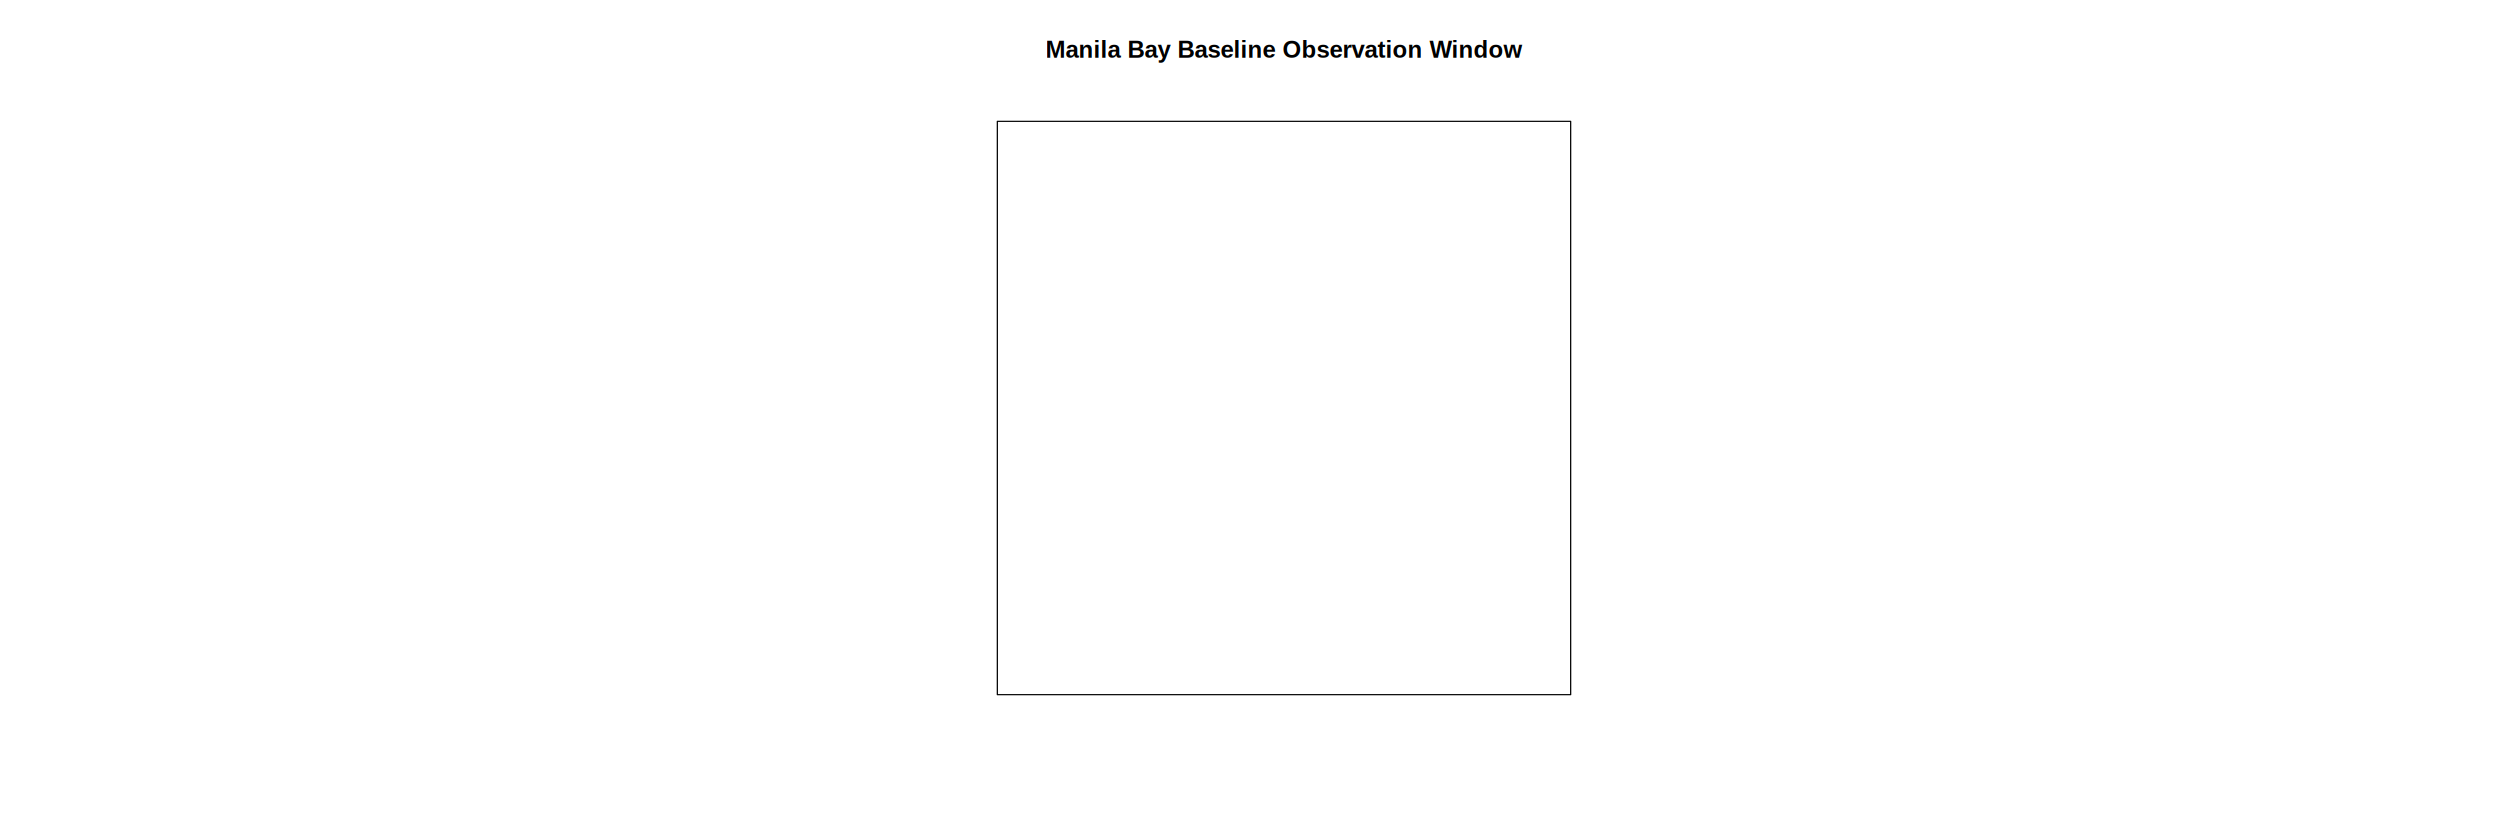

In [27]:

# SIDE FOLDER EXPORT
png(filename = "Day02_Baseline_Observation_Window.png", width = 2000, height = 2000, res = 300)
plot(manila_bay_window, main = "Manila Bay Baseline Observation Window")
dev.off()

# DISPLAY
plot(manila_bay_window, main = "Manila Bay Baseline Observation Window")


### **Observation Window Definition**

The geometric bounding box for the study area is mathematically defined as:
**$W \subset \mathbb{R}^2$**

*   **$W$**: Represents the "Window" of observation (the specific Manila Bay bounding box from 14.3°N–14.8°N and 120.5°E–121.0°E).
*   **$\subset$**: The mathematical symbol for "is a subset of" or "is strictly contained within".
*   **$\mathbb{R}^2$**: Represents two-dimensional real coordinate space (in this specific case, the two-dimensional geographic plane defined by Longitude and Latitude).

---

In spatial point process modeling, stochastic events must be evaluated within a strictly defined, bounded spatial domain [3]. By defining $W \subset \mathbb{R}^2$, we formally establish that the maritime traffic analysis is strictly limited to this finite 2D geographic region [2, 5, 6]. This parameter is mathematically mandatory for the `spatstat` package to calculate the correct area dimensions and perform proper spatial edge-corrections later in the model [4].

DAY 3

In [4]:
# 1. Install and load the geodata package to pull GADM shapefiles directly
install.packages("geodata")
library(geodata)
library(sf)

# 2. Download the high-resolution Philippine boundary shapefile (Level 0)
phl_boundary <- gadm(country = "PHL", level = 0, path = tempdir())

# 3. Convert it to an 'sf' spatial object so it is ready to be intersected
phl_coast_sf <- st_as_sf(phl_boundary)

# 4. Print a confirmation
print("Philippine Coastline successfully imported and converted to an sf object!")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘terra’


Loading required package: terra


Attaching package: ‘terra’


The following objects are masked from ‘package:spatstat.geom’:

    area, delaunay, is.empty, rescale, rotate, shift, where.max,
    where.min


Cached as: /tmp/RtmpdQBfXc/gadm/gadm41_PHL_0_pk.rds



[1] "Philippine Coastline successfully imported and converted to an sf object!"


In [5]:
# 1. Define Manila Bay bounding box as an 'sf' object
# (Matching the exact coordinates from Day 2)
manila_bbox <- st_bbox(c(xmin = 120.5, xmax = 121.0, ymin = 14.3, ymax = 14.8),
                       crs = st_crs(phl_coast_sf))
manila_bbox_sf <- st_as_sfc(manila_bbox)

# 2. Intersect (crop) the massive Philippine coastline down to bounding box
manila_bay_coast <- st_intersection(phl_coast_sf, manila_bbox_sf)

# 3. Print a confirmation message
print("Successfully cropped the Philippine coastline to the Manila Bay bounding box!")

Warning message:
“attribute variables are assumed to be spatially constant throughout all geometries”


[1] "Successfully cropped the Philippine coastline to the Manila Bay bounding box!"


[1] "Successfully generated the non-convex marine observation window!"


agg_record_16a161ae2c0 
                     2

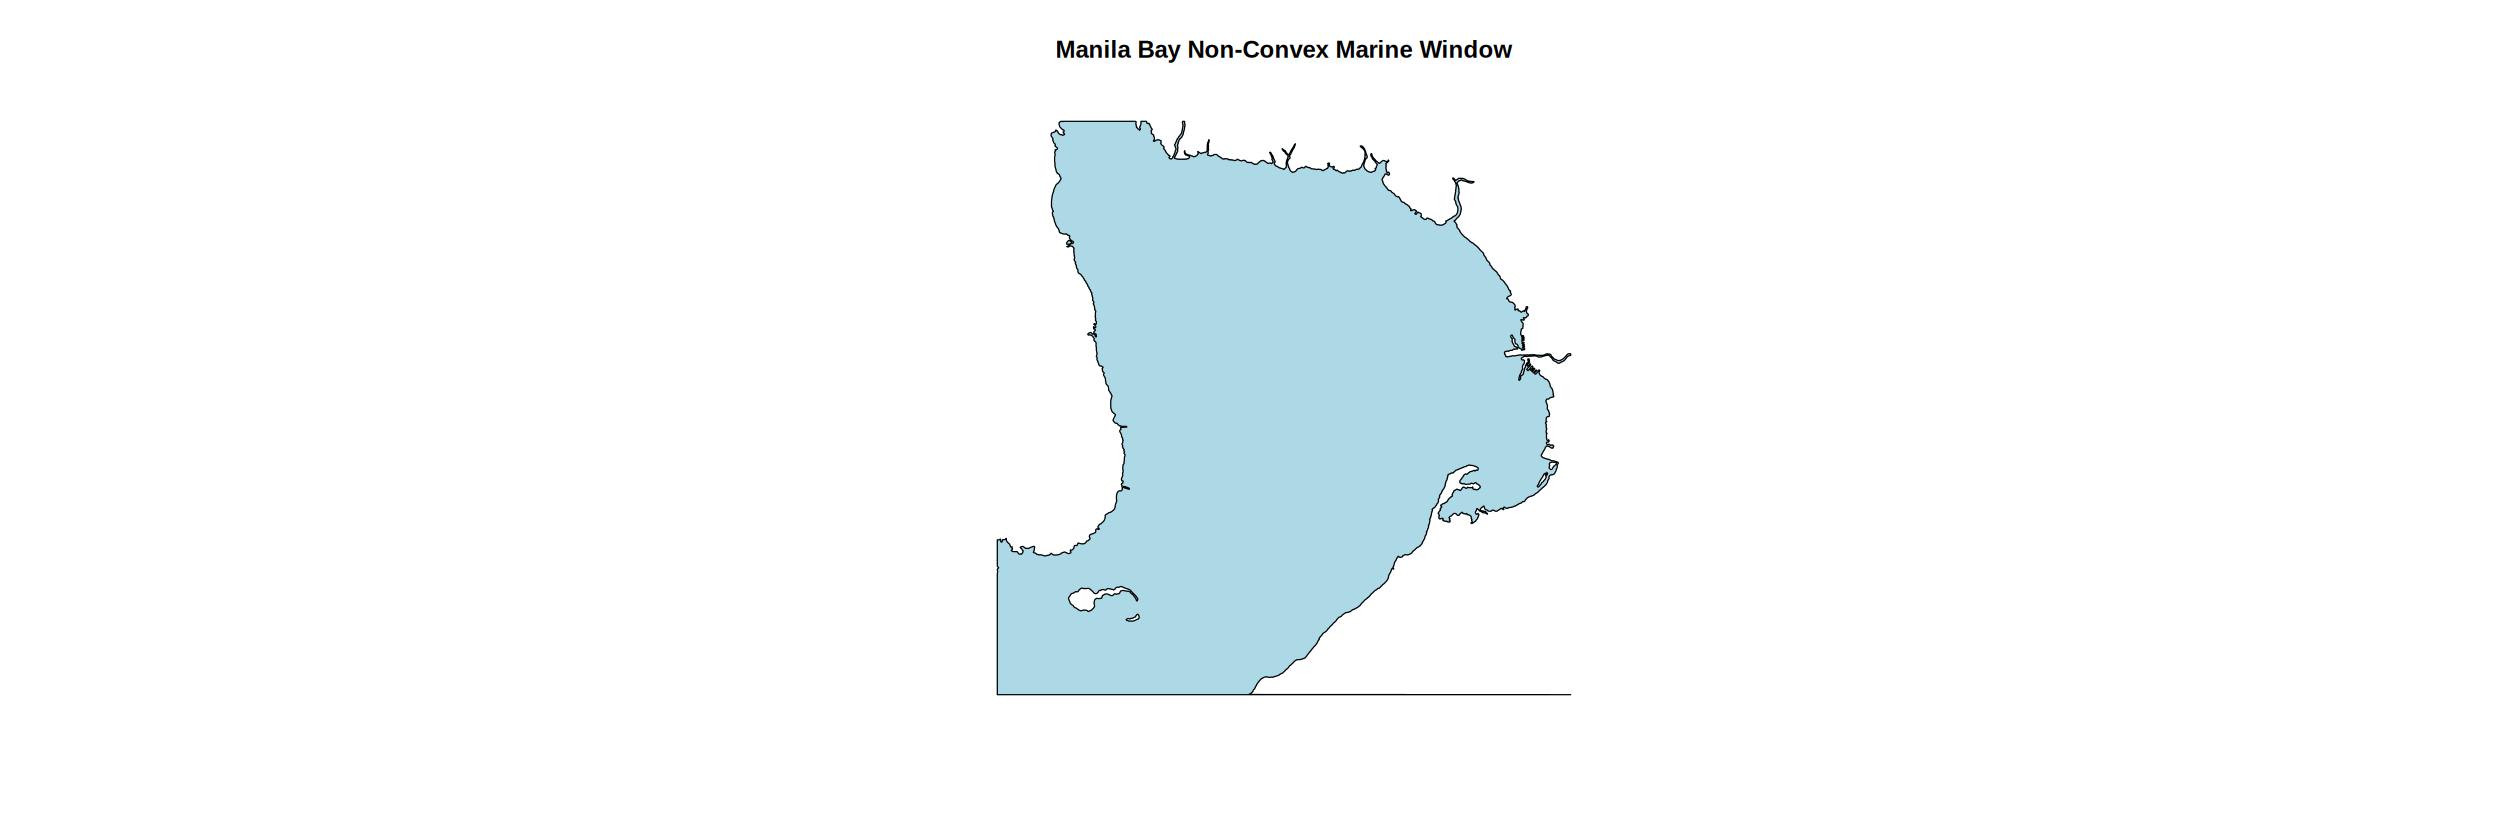

In [33]:

# 1. Strip the geographic CRS tag so spatstat stops blocking the conversion
manila_bay_coast_flat <- st_set_crs(manila_bay_coast, NA)

# 2. Convert the flattened 'sf' landmass object into a spatstat 'owin' object
land_owin <- as.owin(manila_bay_coast_flat)

# 3. Subtract the landmass from the baseline bounding box to create the pure marine window
marine_window <- setminus.owin(manila_bay_window, land_owin)

# 4. Print confirmation message
print("Successfully generated the non-convex marine observation window!")

# 5. Save high-resolution image to side folder
png(filename = "Day03_Non_Convex_Marine_Window.png", width = 2000, height = 2000, res = 300)
plot(marine_window, main = "Manila Bay Non-Convex Marine Window", col = "lightblue")
dev.off()

# 6. Display plot directly in Colab output cell
plot(marine_window, main = "Manila Bay Non-Convex Marine Window", col = "lightblue")


DAY 4

Warning message:
“900900 points were rejected as lying outside the specified window”
Warning message:
“685694 points were rejected as lying outside the specified window”


agg_record_16a513f13f6 
                     2

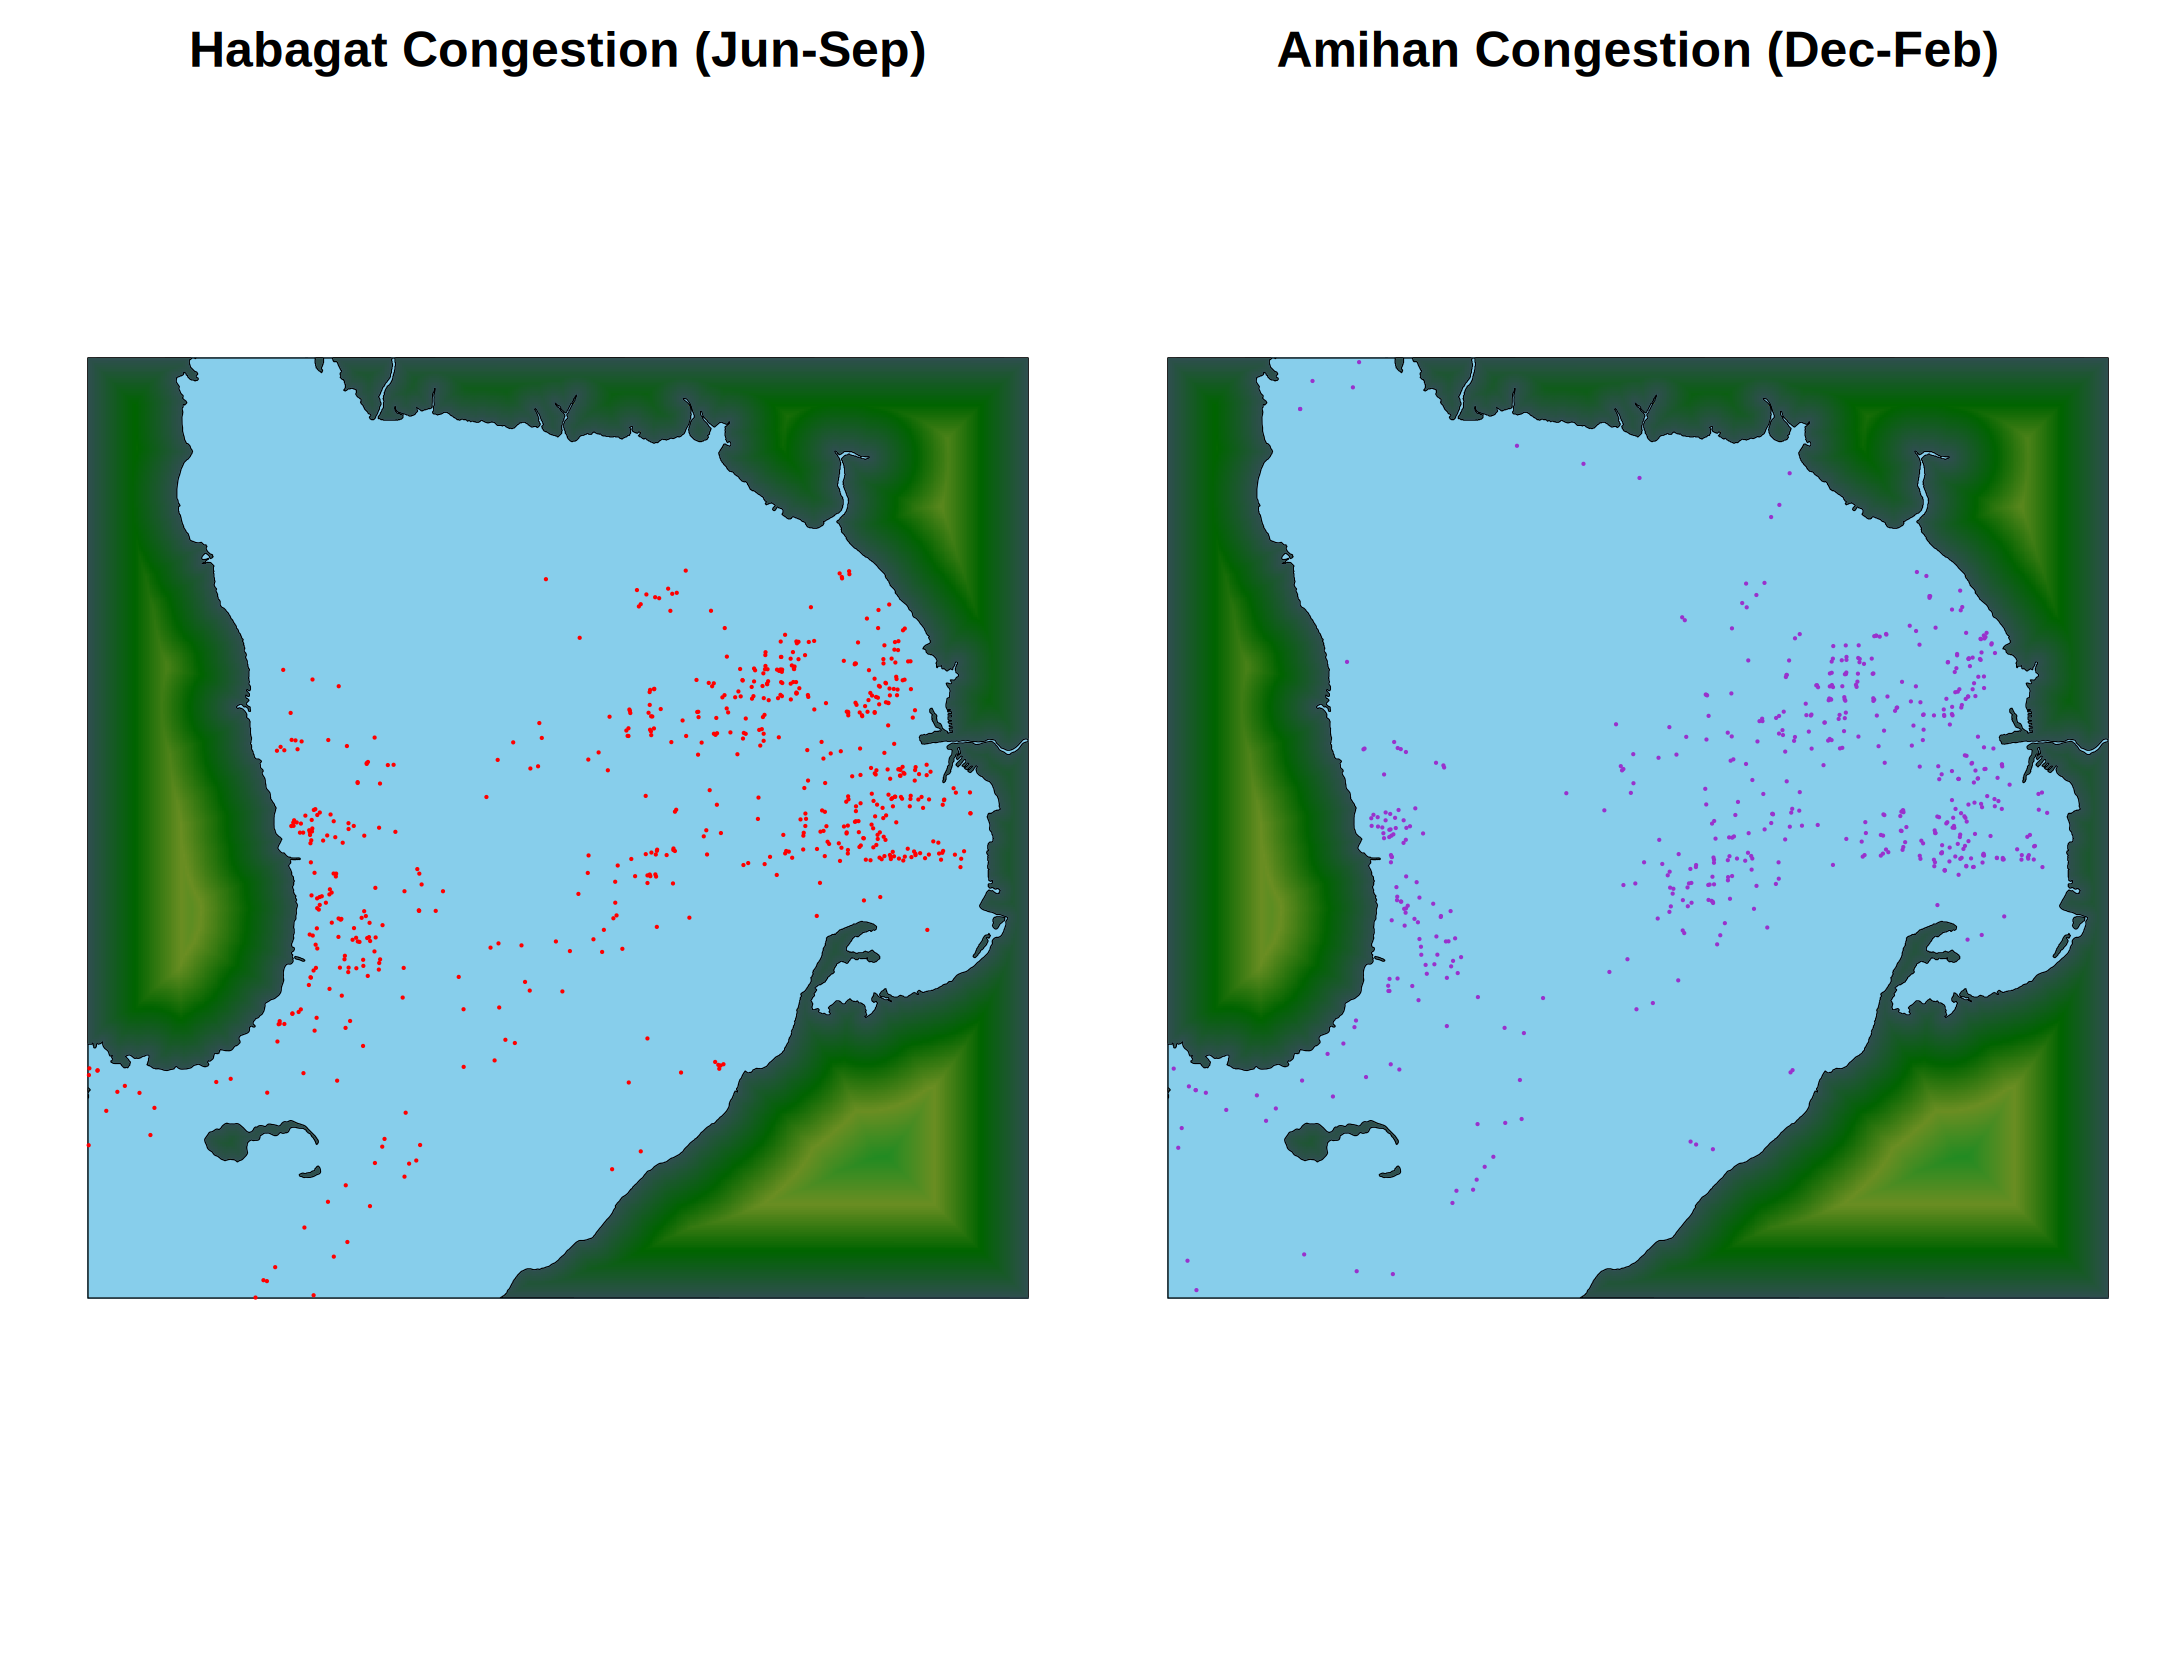

In [35]:
# SEASONAL POINT PATTERN INGESTION (HABAGAT & AMIHAN)

# 1. Force Google Colab to render a plot
options(repr.plot.width = 18, repr.plot.height = 14)

# 2. Read all Habagat and Amihan files
habagat_files <- list.files(pattern = "GFW_SAR_Habagat_.*\\.csv")
amihan_files  <- list.files(pattern = "GFW_SAR_Amihan_.*\\.csv")
habagat_data  <- do.call(rbind, lapply(habagat_files, read.csv))
amihan_data   <- do.call(rbind, lapply(amihan_files, read.csv))

# 3. Extract longitude and latitude
coords_H <- na.omit(habagat_data[, c("lon", "lat")])
coords_A <- na.omit(amihan_data[, c("lon", "lat")])

# 4. Create the ppp objects mapped to marine window
ppp_habagat <- ppp(x = coords_H$lon, y = coords_H$lat, window = marine_window)
ppp_amihan  <- ppp(x = coords_A$lon, y = coords_A$lat, window = marine_window)

# 5. Permanently delete the rejected points from memory
ppp_habagat <- ppp_habagat[marine_window]
ppp_amihan  <- ppp_amihan[marine_window]

# 6. Generate the REALISTIC Earth Gradient (High Resolution)
land_gradient <- bdist.pixels(land_owin, dimyx = 512)
land_gradient <- land_gradient[land_owin, drop = FALSE]

# 7. Earth palette definition
earth_palette <- colorRampPalette(c("darkslategray", "darkgreen", "olivedrab", "forestgreen"))(256)

# ---> ADDED FOR SIDE FOLDER EXPORT
png(filename = "Day04_Seasonal_Point_Pattern_Ingestion.png", width = 3000, height = 1500, res = 300)
par(mfrow = c(1, 2), cex.main = 2.5, mar = c(5, 2, 4, 0.5) + 0.1)

# --- HABAGAT MAP ---
plot(manila_bay_window, main = "Habagat Congestion (Jun-Sep)", col = "white")
plot(land_owin, add = TRUE, col = "darkolivegreen")
plot(land_gradient, add = TRUE, col = earth_palette, ribbon = FALSE)
plot(marine_window, add = TRUE, col = "skyblue")
plot(ppp_habagat, add = TRUE, pch = 20, cex = 0.5, col = "red")

# --- AMIHAN MAP ---
plot(manila_bay_window, main = "Amihan Congestion (Dec-Feb)", col = "white")
plot(land_owin, add = TRUE, col = "darkolivegreen")
plot(land_gradient, add = TRUE, col = earth_palette, ribbon = FALSE)
plot(marine_window, add = TRUE, col = "skyblue")
plot(ppp_amihan, add = TRUE, pch = 20, cex = 0.5, col = "darkorchid")

par(mfrow = c(1, 1))
dev.off()

# ---> DISPLAY PLOT IN COLAB SCREEN
par(mfrow = c(1, 2), cex.main = 2.5, mar = c(5, 2, 4, 0.5) + 0.1)

# --- HABAGAT MAP ---
plot(manila_bay_window, main = "Habagat Congestion (Jun-Sep)", col = "white")
plot(land_owin, add = TRUE, col = "darkolivegreen")
plot(land_gradient, add = TRUE, col = earth_palette, ribbon = FALSE)
plot(marine_window, add = TRUE, col = "skyblue")
plot(ppp_habagat, add = TRUE, pch = 20, cex = 0.5, col = "red")

# --- AMIHAN MAP ---
plot(manila_bay_window, main = "Amihan Congestion (Dec-Feb)", col = "white")
plot(land_owin, add = TRUE, col = "darkolivegreen")
plot(land_gradient, add = TRUE, col = earth_palette, ribbon = FALSE)
plot(marine_window, add = TRUE, col = "skyblue")
plot(ppp_amihan, add = TRUE, pch = 20, cex = 0.5, col = "darkorchid")

par(mfrow = c(1, 1))



### **Proxy Point Pattern Ingestion**

The generated spatial point pattern is mathematically defined as:
**$\mathbf{X} = \{s_1, \dots, s_n\} \subset W$**

* **$\mathbf{X}$**: Represents the stochastic spatial point pattern of the observed fleet, where both the total number of events and their specific spatial locations are treated as random variables within the defined geographic area (Cressie, 1993; Diggle, 2013).
* **$\{s_1, \dots, s_n\}$**: Represents the exact latitude and longitude coordinates of individual vessels extracted from the SAR data, serving as the discrete spatial events within the state space (Kroodsma et al., 2018).
* **$\subset W$**: Proves that the set of vessel points is a *strict subset* of the non-convex marine observation window ($W$). It provides the mathematical proof that the landmasses were successfully subtracted ($W \cap \text{Land} = \emptyset$), establishing the precise polygonal domain required by the `spatstat` package to correctly reject all 685,694 illegal coordinate points falling outside the bay, while setting the boundary foundations necessary to prevent subsequent spatial correlation functions from improperly crossing physical land barriers (Baddeley & Turner, 2005; Bakka et al., 2019).

DAY 5

### ***Week 1 Insight Summary:***
---

The Week 1 pipeline successfully ingested the interim proxy point patterns from the Global Fishing Watch (GFW) dataset. The non-convex marine window for Manila Bay was properly constructed, successfully subtracting landmass boundaries so that $W \cap \text{Land} = \emptyset$. Because GFW relies on AIS transmissions which may contain irregular pings or gaps, the current coordinate matrix serves as a sparse proxy. The R environment and `spatstat` pipeline are now fully stable and prepared for the "Plug-and-Play" protocol, allowing an immediate data swap once the high-resolution, radar-derived matrices from the PhilSA DALOI portal arrive.

DAY 6

png 
  3

agg_record_16a5f56b58f 
                     2

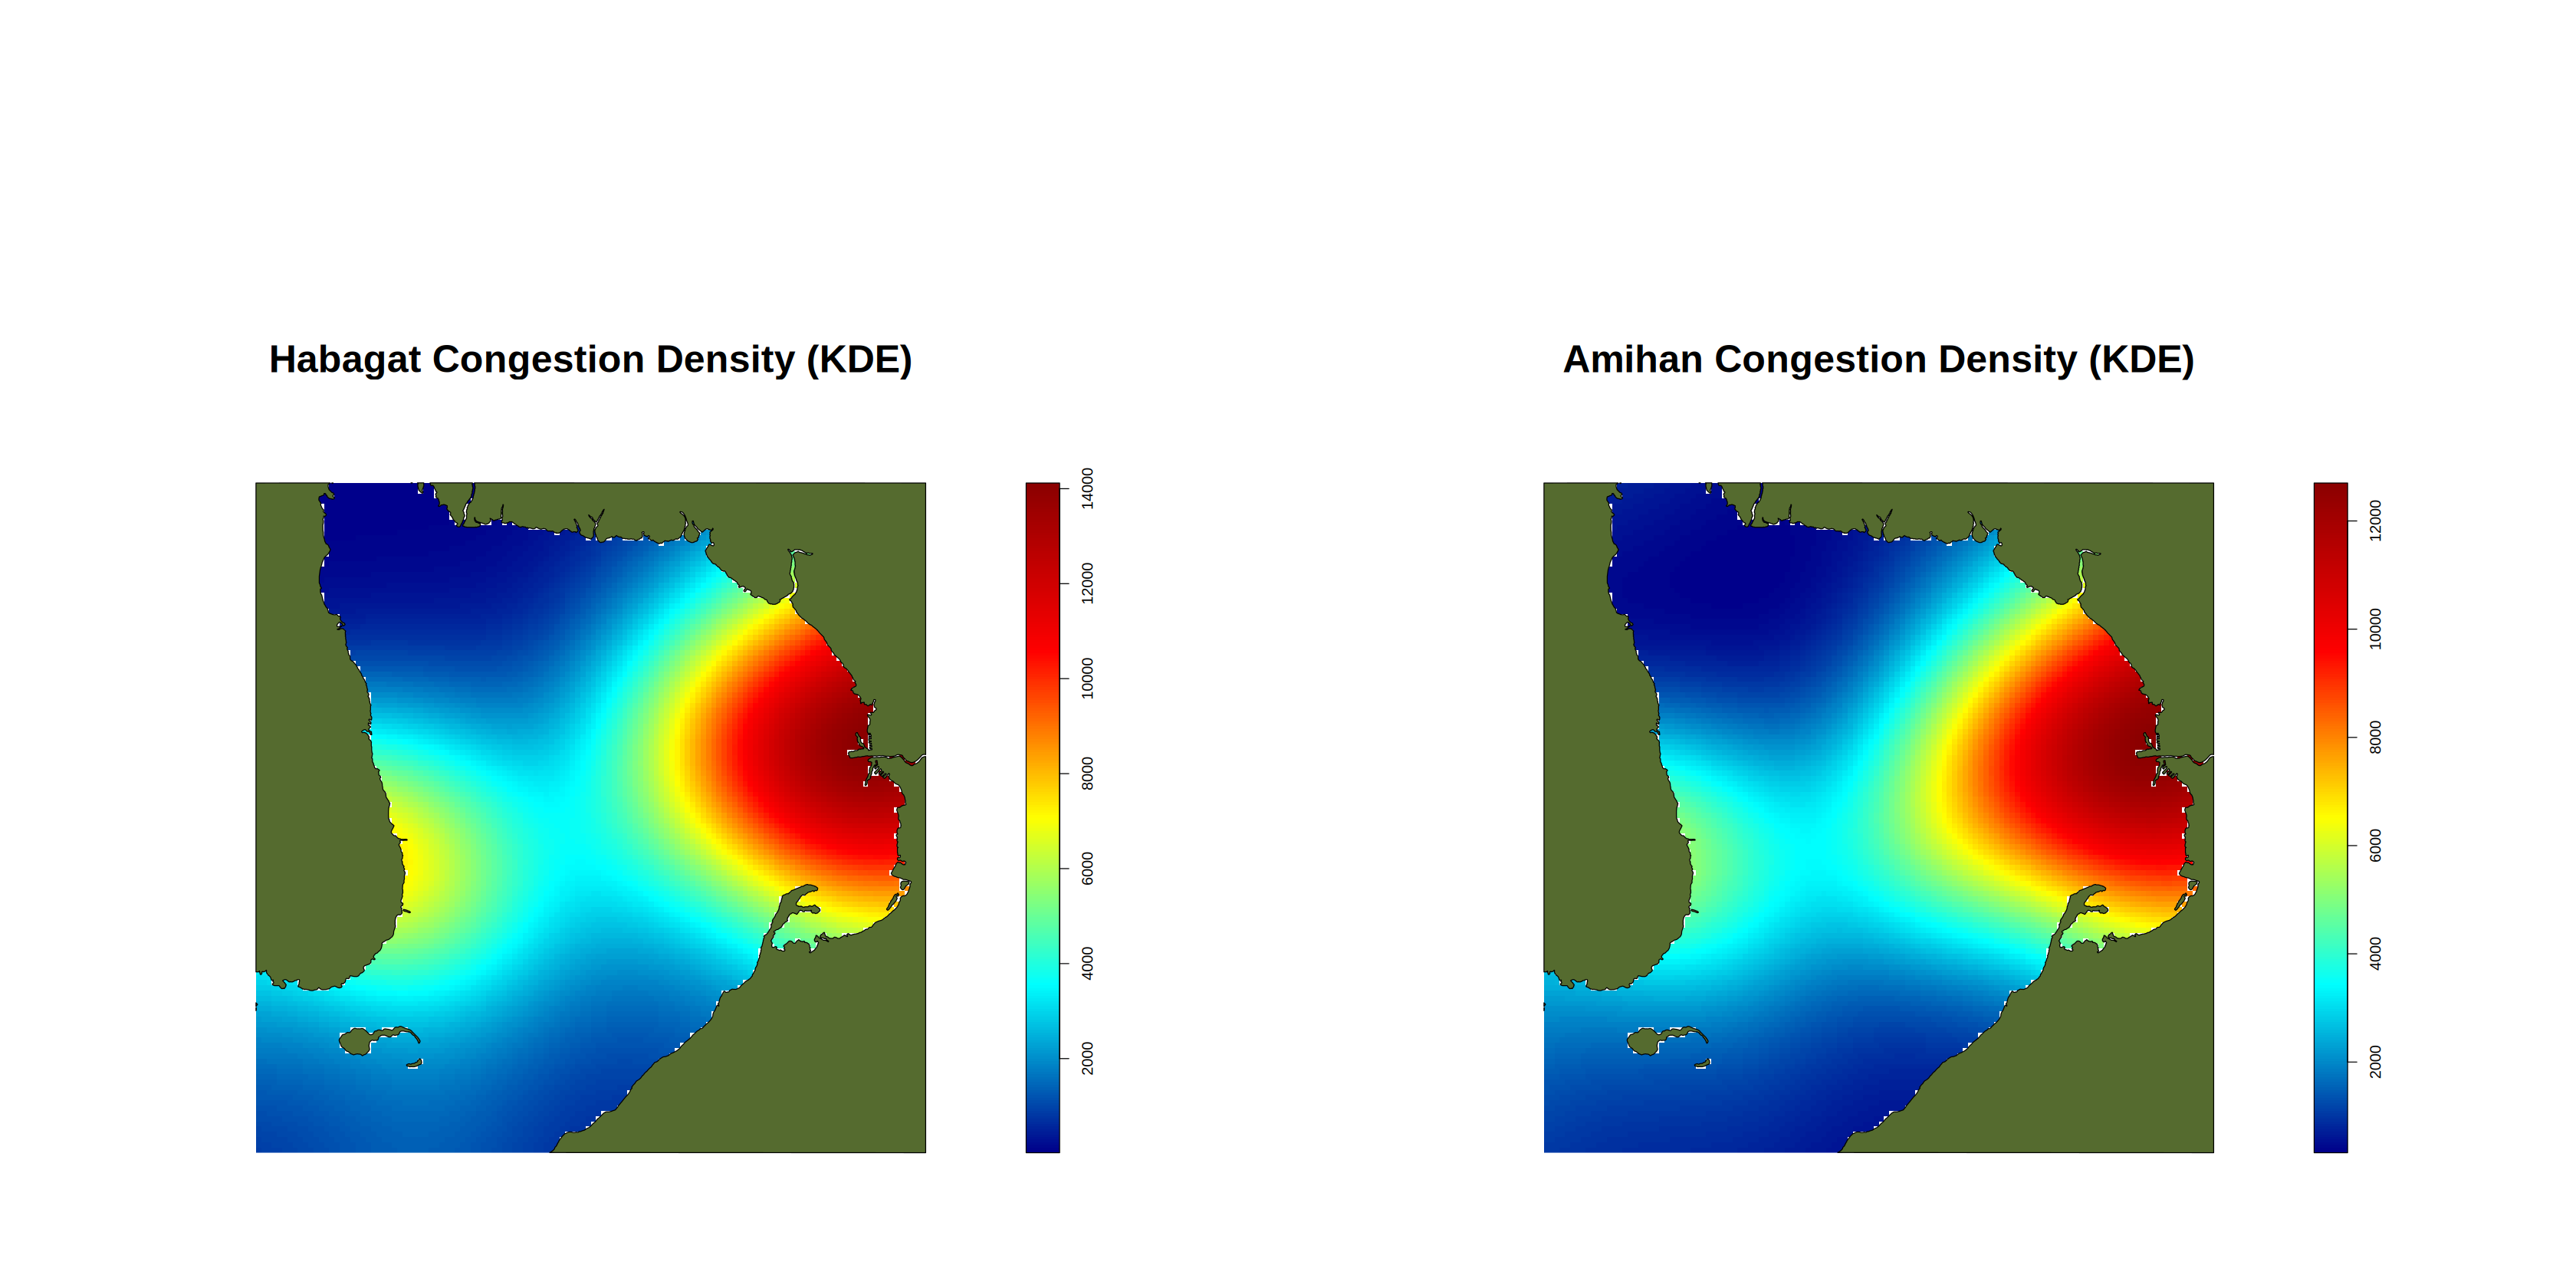

In [37]:

# Spatial Intensity Heatmaps (Kernel Density Estimation)
# 1. Force the massive plot size to match baseline maps
options(repr.plot.width = 28, repr.plot.height = 14)

# 2. Calculate the Kernel Density Estimation (KDE) for both seasons
# This transforms the discrete vessel points into a continuous density surface
kde_habagat <- density.ppp(ppp_habagat)
kde_amihan  <- density.ppp(ppp_amihan)

# 3. Create a high-contrast heatmap color palette (Deep Ocean Blue to Hot Red)
heat_palette <- colorRampPalette(c("darkblue", "cyan", "yellow", "red", "darkred"))(256)

# 4. Set the plotting parameters (using exact preferred margins)
par(mfrow=c(1,2), cex.main=2.5, mar=c(5, 2, 4, 0.5) + 0.1)

# --- HABAGAT KDE MAP ---
plot(kde_habagat, main = "Habagat Congestion Density (KDE)", col = heat_palette)
# Overlay the realistic landmass so the coastline remains perfectly defined
plot(land_owin, add = TRUE, col = "darkolivegreen")

# --- AMIHAN KDE MAP ---
plot(kde_amihan, main = "Amihan Congestion Density (KDE)", col = heat_palette)
plot(land_owin, add = TRUE, col = "darkolivegreen")

par(mfrow=c(1,1))

# Seamless side folder export (copies on-screen plot directly to PNG)
dev.copy(png, filename = "Day06_Spatial_Intensity_KDE.png", width = 3000, height = 1500, res = 300)
dev.off()


### **First-Order Empirical Intensity Estimation**

The empirical spatial intensity of the maritime traffic is derived using Kernel Density Estimation (KDE), mathematically anchored by the first-order intensity expected value equation (Diggle, 2013):

**$$ \lambda(s) = \lim_{\|ds\| \to 0} \frac{\mathbb{E}[N(ds)]}{\|ds\|} $$**

* **$\lambda(s)$**: The first-order spatial intensity function, representing the expected density of vessels at a specific location $s$ (Møller & Waagepetersen, 2004).
* **$\mathbb{E}[N(ds)]$**: The expected number of points (vessel occurrences) falling within an infinitesimally small spatial region $ds$ (Daley & Vere-Jones, 2007).
* **$\|ds\|$**: The two-dimensional area of that infinitesimal region.



By evaluating this limit, the discrete vessel coordinates are transformed into a continuous statistical surface. If we assume no multiple points can fall into the exact same infinitesimal region, this limit yields the pure spatial density of points over the domain (Illian et al., 2008). This allows us to formally pinpoint the highest concentrations of maritime congestion across the non-convex observation window for both monsoons.

DAY 7

Warning message:
“Some expected counts are small; chi^2 approximation may be inaccurate”
Warning message:
“Some expected counts are small; chi^2 approximation may be inaccurate”


[1] "--- HABAGAT CSR TEST RESULTS ---"

	Chi-squared test of CSR using quadrat counts

data:  
X2 = 885.21, df = 24, p-value < 2.2e-16
alternative hypothesis: two.sided

Quadrats: 25 tiles (irregular windows)
[1] "--- AMIHAN CSR TEST RESULTS ---"

	Chi-squared test of CSR using quadrat counts

data:  
X2 = 801.47, df = 24, p-value < 2.2e-16
alternative hypothesis: two.sided

Quadrats: 25 tiles (irregular windows)


png 
  3

agg_record_16a23ff73e 
                    2

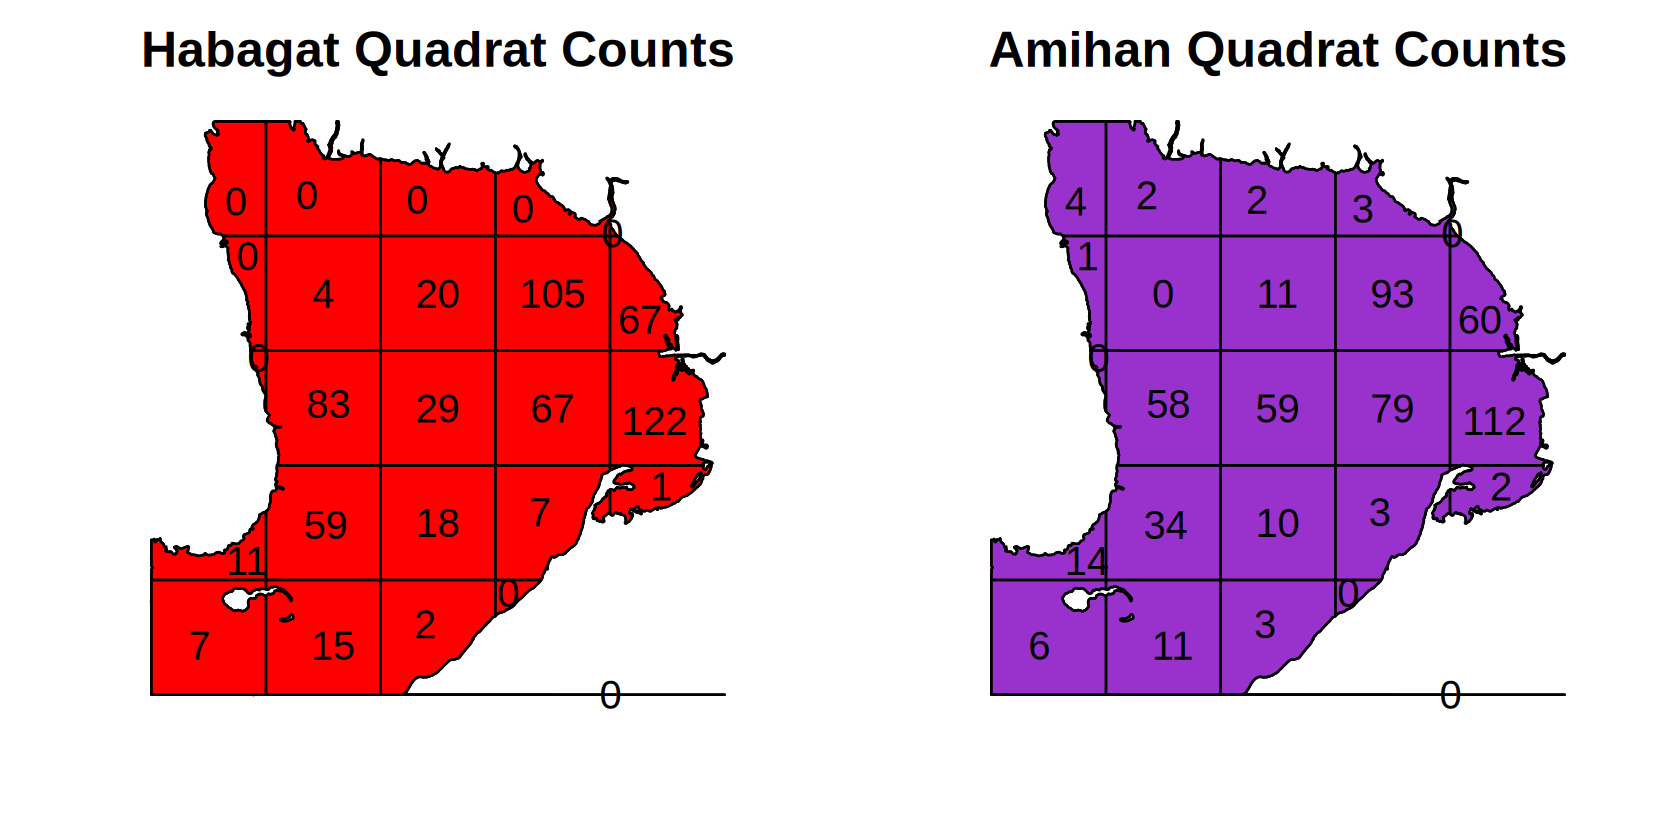

In [39]:

# Complete Spatial Randomness (CSR) Testing
# Quadrat Counting (Dividing the bay into a 5x5 grid)
q_count_habagat <- quadratcount(ppp_habagat, nx = 5, ny = 5)
q_count_amihan  <- quadratcount(ppp_amihan, nx = 5, ny = 5)

# Chi-Squared Hypothesis Test
csr_test_habagat <- quadrat.test(q_count_habagat)
csr_test_amihan  <- quadrat.test(q_count_amihan)

# Print the statistical results to the console
print("--- HABAGAT CSR TEST RESULTS ---")
print(csr_test_habagat)
print("--- AMIHAN CSR TEST RESULTS ---")
print(csr_test_amihan)

# Graph the quadrat grid overlaid with vessel counts
options(repr.plot.width = 14, repr.plot.height = 7)
par(mfrow=c(1,2), cex.main=2.5, mar=c(5, 2, 4, 0.5) + 0.1)

# Plot Habagat points and overlay the grid with counts
plot(ppp_habagat, main = "Habagat Quadrat Counts", pch = 20, cex = 0.5, col = "red")
plot(q_count_habagat, add = TRUE, cex = 2, col = "black", lwd = 2)

# Plot Amihan points and overlay the grid with counts
plot(ppp_amihan, main = "Amihan Quadrat Counts", pch = 20, cex = 0.5, col = "darkorchid")
plot(q_count_amihan, add = TRUE, cex = 2, col = "black", lwd = 2)

par(mfrow=c(1,1))

dev.copy(png, filename = "Day07_Quadrat_Counts.png", width = 3000, height = 1500, res = 300)
dev.off()



### **Mathematical Audit: Pearson Chi-Squared Goodness-of-Fit Test**

To formally evaluate the null hypothesis ($H_0$) of Complete Spatial Randomness (CSR), a quadrat counting method was applied, partitioning the non-convex observation window into a 5x5 grid to calculate observed versus expected vessel frequencies (DataCamp, n.d.). The statistical significance of spatial clustering was evaluated using the Pearson chi-squared goodness-of-fit test statistic:
**$$ X^2 = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i} $$**

* **$X^2$**: The Pearson chi-squared test statistic.
* **$O_i$**: The observed number of vessel occurrences within quadrat $i$.
* **$E_i$**: The expected number of vessels in quadrat $i$ under the assumption of a homogeneous Poisson point process.

The analysis yielded $X^2$ values of 885.21 (Habagat) and 801.47 (Amihan), both resulting in $p$-values $< 2.2 \times 10^{-16}$. Because the $p$-value is drastically lower than the standard $\alpha = 0.05$ threshold, we strictly reject the null hypothesis of CSR. This mathematical rejection demonstrates that the spatial distribution of maritime traffic significantly deviates from complete spatial randomness, exhibiting strong clustering behavior, thereby validating the necessity to model the fleet distributions using an inhomogeneous Log-Gaussian Cox Process (LGCP) capable of incorporating latent environmental covariates (DataCamp, n.d.).


*(Note: The minor computational warnings regarding small expected counts arise strictly due to the geometric irregularities of the non-convex coastline intersecting the rigid 5x5 quadrat grid, creating marginal tiles with near-zero expected vessel occurrences; however, the massive magnitude of the test statistics ensures the rejection of $H_0$ is robust.)*

DAY 8

In [11]:
# 1. Install the terra package directly into Colab cloud kernel
install.packages("terra")

# 2. Load the terra library into active R session so you can use it
library(terra)

# 3. Load spatstat for point pattern and window tools
library(spatstat)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



png 
  3

agg_record_16ab7b4daf 
                    2

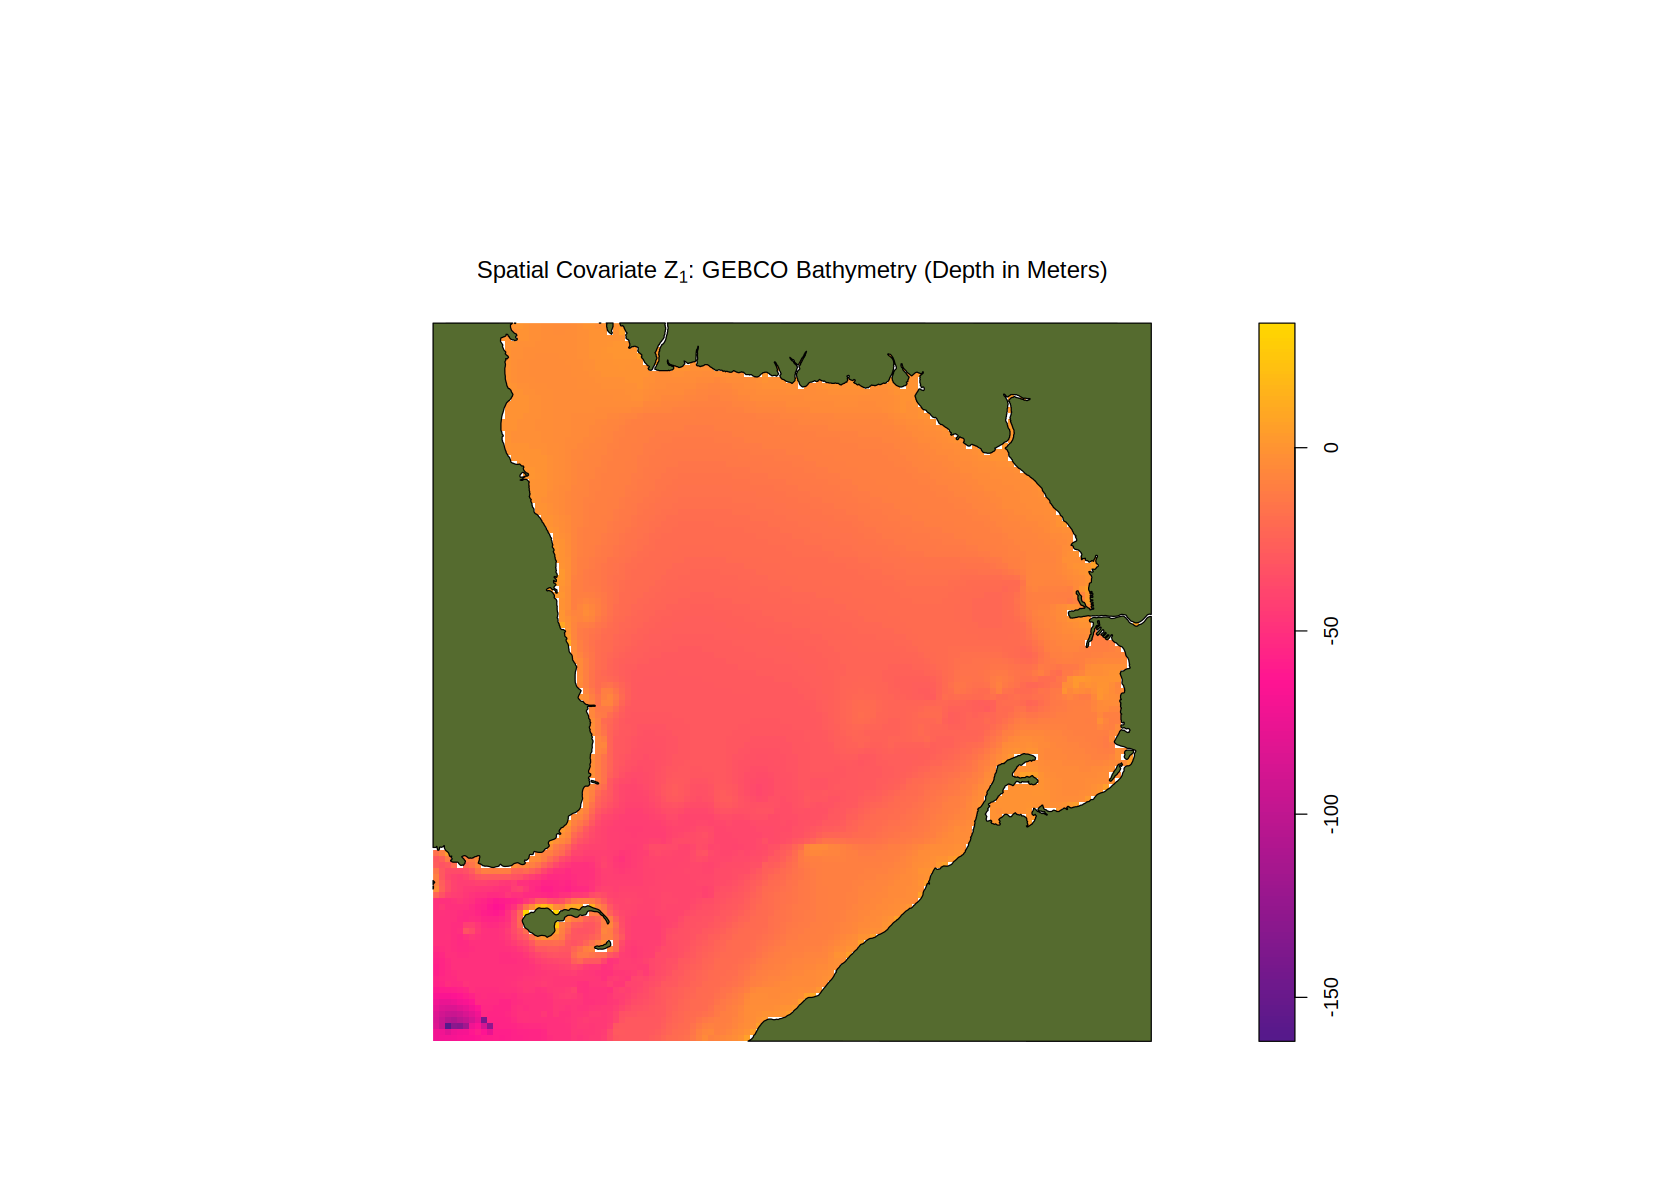

In [41]:

# ENVIRONMENTAL COVARIATE EXTRACTION (BATHYMETRY)
library(terra)
library(spatstat)

gebco_raster <- rast("gebco_bathymetry.tif")
manila_ext <- ext(120.5, 121.0, 14.3, 14.8)
cropped_gebco <- crop(gebco_raster, manila_ext)

# THE FATAL BUG FIX: na.rm = FALSE prevents R from silently deleting the western ocean boundary!
gebco_df <- as.data.frame(cropped_gebco, xy = TRUE, na.rm = FALSE)
colnames(gebco_df) <- c("x", "y", "depth")

Z1_bathymetry_raw <- as.im(gebco_df)

# Clip continuous bathymetric surface to non-convex marine window
Z1_bathymetry <- Z1_bathymetry_raw[marine_window, drop = FALSE]

# Color palette definition for Bathymetry (Purple to Gold)
plasma_pal <- colorRampPalette(c("purple4", "deeppink", "gold"))(256)

options(repr.plot.width = 14, repr.plot.height = 10)

# Graph Covariate Z1
plot(Z1_bathymetry, main = expression(paste("Spatial Covariate ", Z[1], ": GEBCO Bathymetry (Depth in Meters)")), col = plasma_pal)
plot(land_owin, add = TRUE, col = "darkolivegreen")

dev.copy(png, filename = "Day08_Bathymetry_Covariate.png", width = 2800, height = 2000, res = 300)
dev.off()



### **Inhomogeneous Intensity Formula**
By extracting the continuous bathymetric surface, the framework establishes the first exogenous spatial covariate ($Z_1$). This allows us to model the first-order spatial trend of maritime congestion:

$$ \log \lambda(s) = \beta_0 + \beta_1 Z_1(s) $$

Where $\lambda(s)$ is the expected vessel intensity, $\beta_0$ is the baseline intercept, and $\beta_1$ estimates the degree to which shallow water drafts physically restrict vessel movement and drive bottleneck formations (Moraga, 2020; Renner et al., 2015).


DAY 9

[1] "Successfully generated and clipped Spatial Covariate Z_2: Anchorage Proximity!"
[1] "Successfully smoothed and clipped Spatial Covariate Z_3!"


png 
  3

agg_record_16a5fa8d4ac 
                     2

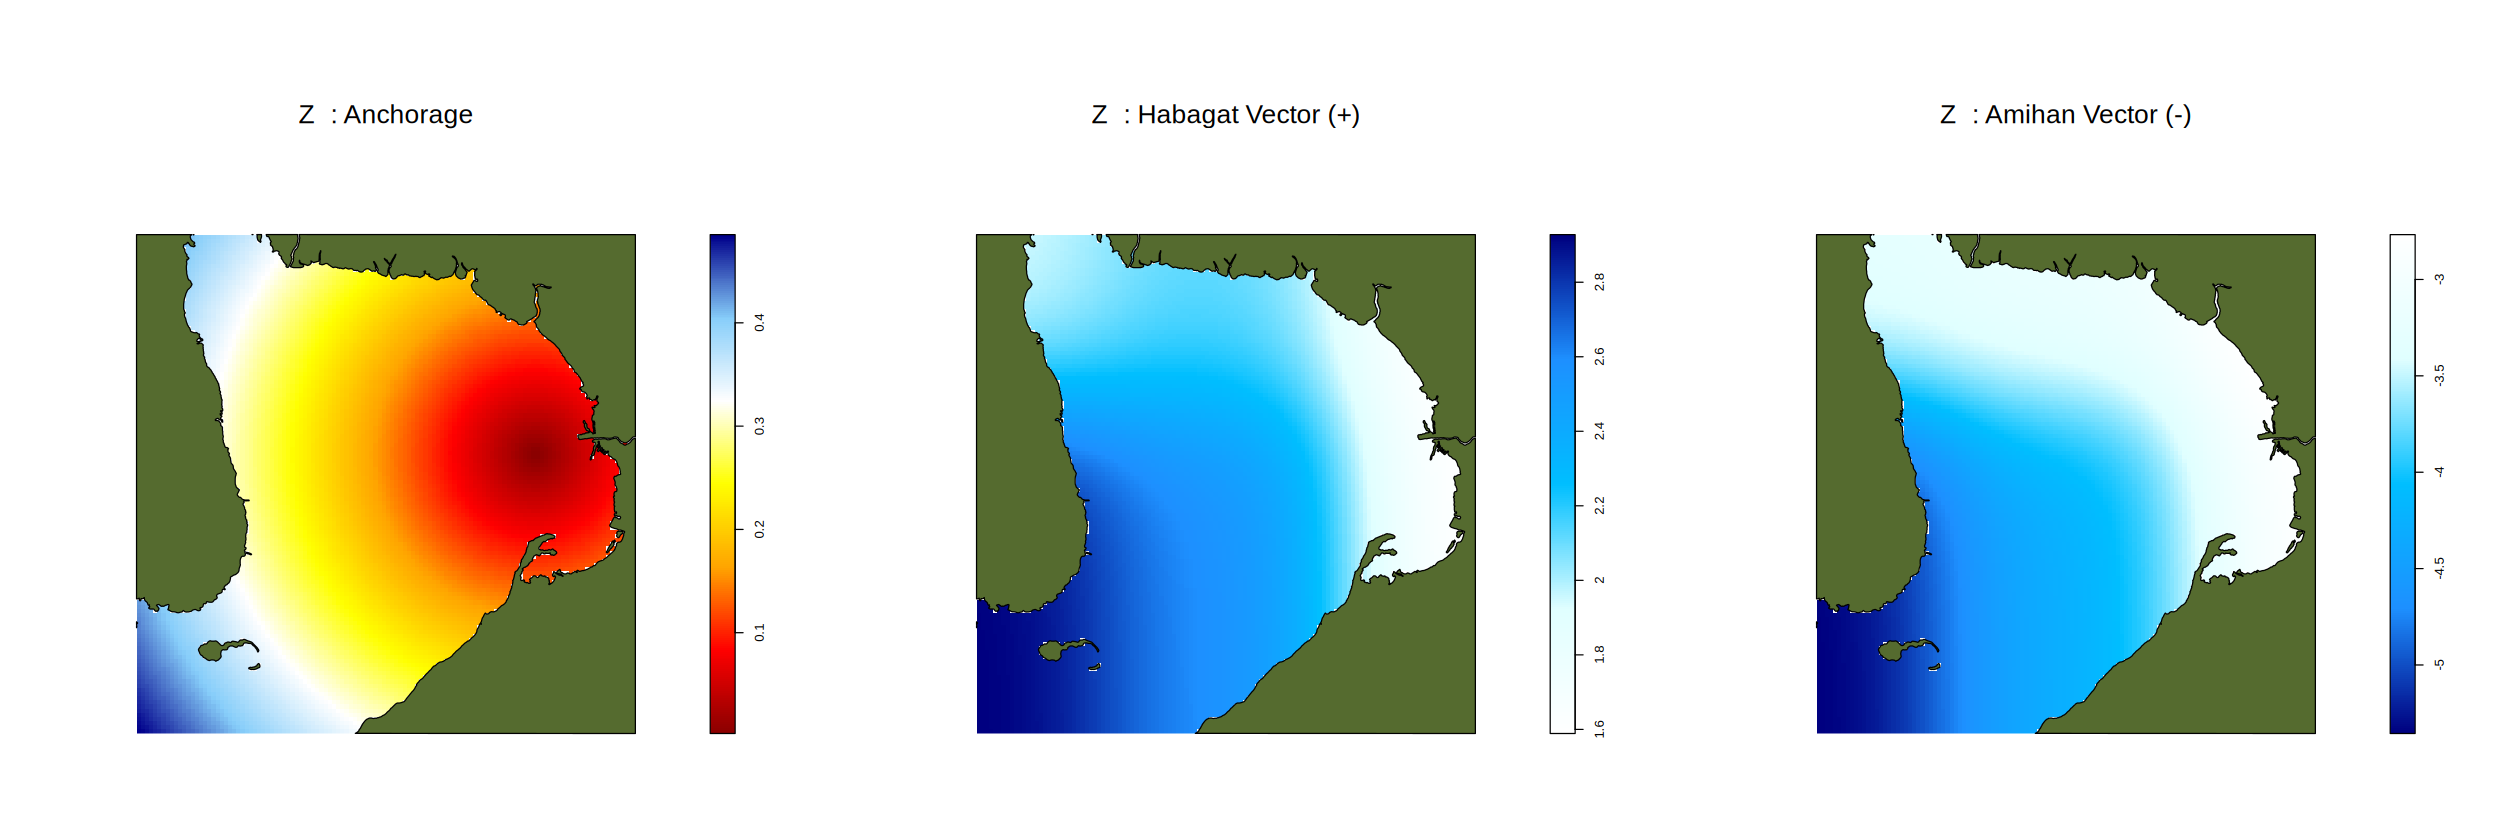

In [42]:

# Infrastructural & Meteorological Covariates
# --- SPATIAL COVARIATE Z2: ANCHORAGE PROXIMITY ---
anchorage_ppp <- ppp(x = 120.9000, y = 14.5800, window = marine_window_aligned)
Z2_raw <- distmap(anchorage_ppp, xy = marine_window_aligned)
Z2_anchorage <- Z2_raw[marine_window_aligned, drop = FALSE]
print("Successfully generated and clipped Spatial Covariate Z_2: Anchorage Proximity!")

# --- SPATIAL COVARIATE Z3: MONSOONAL AXIS WIND PROJECTION ---
library(terra)
library(spatstat)

era5_habagat <- rast("era5_wind_habagat.nc")
era5_amihan <- rast("era5_wind_amihan.nc")

u_mean_H <- mean(era5_habagat[[grep("u10", names(era5_habagat))]])
v_mean_H <- mean(era5_habagat[[grep("v10", names(era5_habagat))]])
u_mean_A <- mean(era5_amihan[[grep("u10", names(era5_amihan))]])
v_mean_A <- mean(era5_amihan[[grep("v10", names(era5_amihan))]])

angle_rad <- 45 * (pi / 180)
force_habagat <- (u_mean_H * cos(angle_rad)) + (v_mean_H * sin(angle_rad))
force_amihan <- (u_mean_A * cos(angle_rad)) + (v_mean_A * sin(angle_rad))

# THE FIX 2: Lower the bandwidth to sigma = 0.1.
# This prevents the homogenization effect, restoring the true variance of the maps.
Z3_raw_H <- Smooth(wind_pts_H, sigma = 0.1, xy = marine_window_aligned)
Z3_raw_A <- Smooth(wind_pts_A, sigma = 0.1, xy = marine_window_aligned)

Z3_wind_H <- Z3_raw_H[marine_window_aligned, drop = FALSE]
Z3_wind_A <- Z3_raw_A[marine_window_aligned, drop = FALSE]
print("Successfully smoothed and clipped Spatial Covariate Z_3!")

# --- CUSTOM COLOR PALETTES FOR PUBLICATION ---
pal_z2 <- colorRampPalette(c("darkred", "red", "orange", "yellow", "white", "lightskyblue", "darkblue"))(256)
pal_habagat <- colorRampPalette(c("white", "lightcyan", "deepskyblue", "dodgerblue", "navy"))(256)
pal_amihan <- colorRampPalette(c("navy", "dodgerblue", "deepskyblue", "lightcyan", "white"))(256)

# --- GRAPH COVARIATES Z2 & Z3 (WITH LANDMASS OVERLAYS) ---
options(repr.plot.width = 21, repr.plot.height = 7)
par(mfrow=c(1,3), cex.main=2)

# THE FIX 3: Native expression subscript syntax
plot(Z2_anchorage, main = expression(Z ~ ": Anchorage"), col=pal_z2)
plot(land_owin, add = TRUE, col = "darkolivegreen")

plot(Z3_wind_H, main = expression(Z ~ ": Habagat Vector (+)"), col=pal_habagat)
plot(land_owin, add = TRUE, col = "darkolivegreen")

plot(Z3_wind_A, main = expression(Z ~ ": Amihan Vector (-)"), col=pal_amihan)
plot(land_owin, add = TRUE, col = "darkolivegreen")

par(mfrow=c(1,1))

dev.copy(png, filename = "Day09_Infrastructural_Meteorological_Covariates.png", width = 3150, height = 1050, res = 300)
dev.off()



#### **1. Mathematical Covariate Formulation**
To complement the bathymetric depth surface ($Z_1$), two additional continuous first-order spatial covariates ($Z_2$ and $Z_3$) were generated and mapped onto the spatial quadrature grid of Manila Bay:

1. **Infrastructural Anchorage Distance Field ($Z_2$):**  
   Evaluates the spatial proximity of vessels to the primary designated port anchorage centroid $u_{\text{anchorage}} \approx (120.95^\circ\text{E}, 14.58^\circ\text{N})$ using an isotropic Euclidean distance metric:

   $$Z_2(u) = \|u - u_{\text{anchorage}}\| = \sqrt{(x - x_{\text{anch}})^2 + (y - y_{\text{anch}})^2}$$

   * **Unit:** Spatial distance in decimal degrees ($\text{deg}$).
   * **Domain Range:** $0.00^\circ$ at the port origin to $\approx 0.48^\circ$ at the southwestern outer bay mouth.

2. **Meteorological Monsoonal Wind Vector Surfaces ($Z_3$):**  
   Derived from ERA5 reanalysis hourly vector fields, representing the directional component of prevailing seasonal surface winds:
   * **Habagat Regime (SW Monsoon, $+Z_3$):** Predominantly positive directional wind vector component ($+1.6 \text{ m/s}$ to $+2.9 \text{ m/s}$) pushing onshore from the Southwest entrance toward the inner bay.
   * **Amihan Regime (NE Monsoon, $-Z_3$):** Predominantly negative directional wind vector component ($-5.2 \text{ m/s}$ to $-2.8 \text{ m/s}$) blowing offshore from the Northeast landmass out toward the open sea.

---

#### **2. Empirical Features &amp; Spatial Gradients**

* **$Z_2$ Anchorage Distance Gradient (Red-to-Blue Spectrum):**  
  Displays a smooth radial potential gradient centered directly on the inner harbor anchorage basin (deep red zone, $< 0.10^\circ$). Distance values increase monotonically outward through the central bay fairway (yellow, $\sim 0.20^\circ$) to the open marine mouth (blue, $> 0.40^\circ$).

* **$Z_3$ Seasonal Atmospheric Forcing Contrast:**  
  * During **Habagat**, wind vector intensities peak along the outer bay mouth ($\sim 2.9 \text{ m/s}$), driving heavy vessel aggregation toward sheltered inner waters.  
  * During **Amihan**, strong offshore winds ($-5.2 \text{ m/s}$) create a protective lee shore along the northern/northeastern coastline, causing vessels to shift anchorage positions closer to land barriers.

---

#### **3. Role in Inhomogeneous Point Process Modeling (Chapter III)**
These spatial rasters serve as first-order exogenous trend predictors in the log-linear intensity function of the inhomogeneous Poisson baseline model ($\text{PPM}$):

$$\log \lambda(u) = \beta_0 + \beta_1 Z_1(u) + \beta_2 Z_2(u) + \beta_3 Z_3(u)$$

By isolating the first-order spatial effects of distance-to-port ($Z_2$) and seasonal wind pressure ($Z_3$), we establish the baseline trend required to test for remaining second-order residual autocorrelation in Day 11.



DAY 10

Warning message:
“Values of the covariates ‘Z1’, ‘Z2’, ‘Z3’ were NA or undefined at 0.15% (5 out of 3291) of the quadrature points. Occurred while executing: ppm.ppp(Q = ppp_habagat, trend = ~Z1 + Z2 + Z3, data = NULL, ”


[1] "Habagat Model Summary:"
Nonstationary Poisson process
Fitted to point pattern dataset ‘ppp_habagat’

Log intensity:  ~Z1 + Z2 + Z3

Fitted trend coefficients:
(Intercept)          Z1          Z2          Z3 
 9.63324097 -0.03105963 -8.77322840 -0.19576664 

               Estimate        S.E.      CI95.lo    CI95.hi Ztest        Zval
(Intercept)  9.63324097 0.413342605   8.82310435 10.4433776   ***  23.3057054
Z1          -0.03105963 0.004374433  -0.03963336 -0.0224859   ***  -7.1002646
Z2          -8.77322840 0.664811741 -10.07623547 -7.4702213   *** -13.1965606
Z3          -0.19576664 0.236292207  -0.65889085  0.2673576        -0.8284938
Problem:
 Values of the covariates ‘Z1’, ‘Z2’, ‘Z3’ were NA or undefined at 
0.15% (5 out of 3291) of the quadrature points



Warning message:
“Values of the covariates ‘Z1’, ‘Z2’, ‘Z3’ were NA or undefined at 0.15% (5 out of 3241) of the quadrature points. Occurred while executing: ppm.ppp(Q = ppp_amihan, trend = ~Z1 + Z2 + Z3, data = NULL, interaction = NULL, ”


[1] "Amihan Model Summary:"
Nonstationary Poisson process
Fitted to point pattern dataset ‘ppp_amihan’

Log intensity:  ~Z1 + Z2 + Z3

Fitted trend coefficients:
  (Intercept)            Z1            Z2            Z3 
  7.213849696  -0.006866796 -12.818953373  -0.796537468 

                 Estimate        S.E.      CI95.lo       CI95.hi Ztest
(Intercept)   7.213849696 0.504984524   6.22409822   8.203601175   ***
Z1           -0.006866796 0.006981807  -0.02055089   0.006817294      
Z2          -12.818953373 0.850220137 -14.48535422 -11.152552526   ***
Z3           -0.796537468 0.186098054  -1.16128295  -0.431791985   ***
                   Zval
(Intercept)  14.2852887
Z1           -0.9835271
Z2          -15.0772168
Z3           -4.2802031
Problem:
 Values of the covariates ‘Z1’, ‘Z2’, ‘Z3’ were NA or undefined at 
0.15% (5 out of 3241) of the quadrature points



png 
  3

agg_record_16a2c7ca28c 
                     2

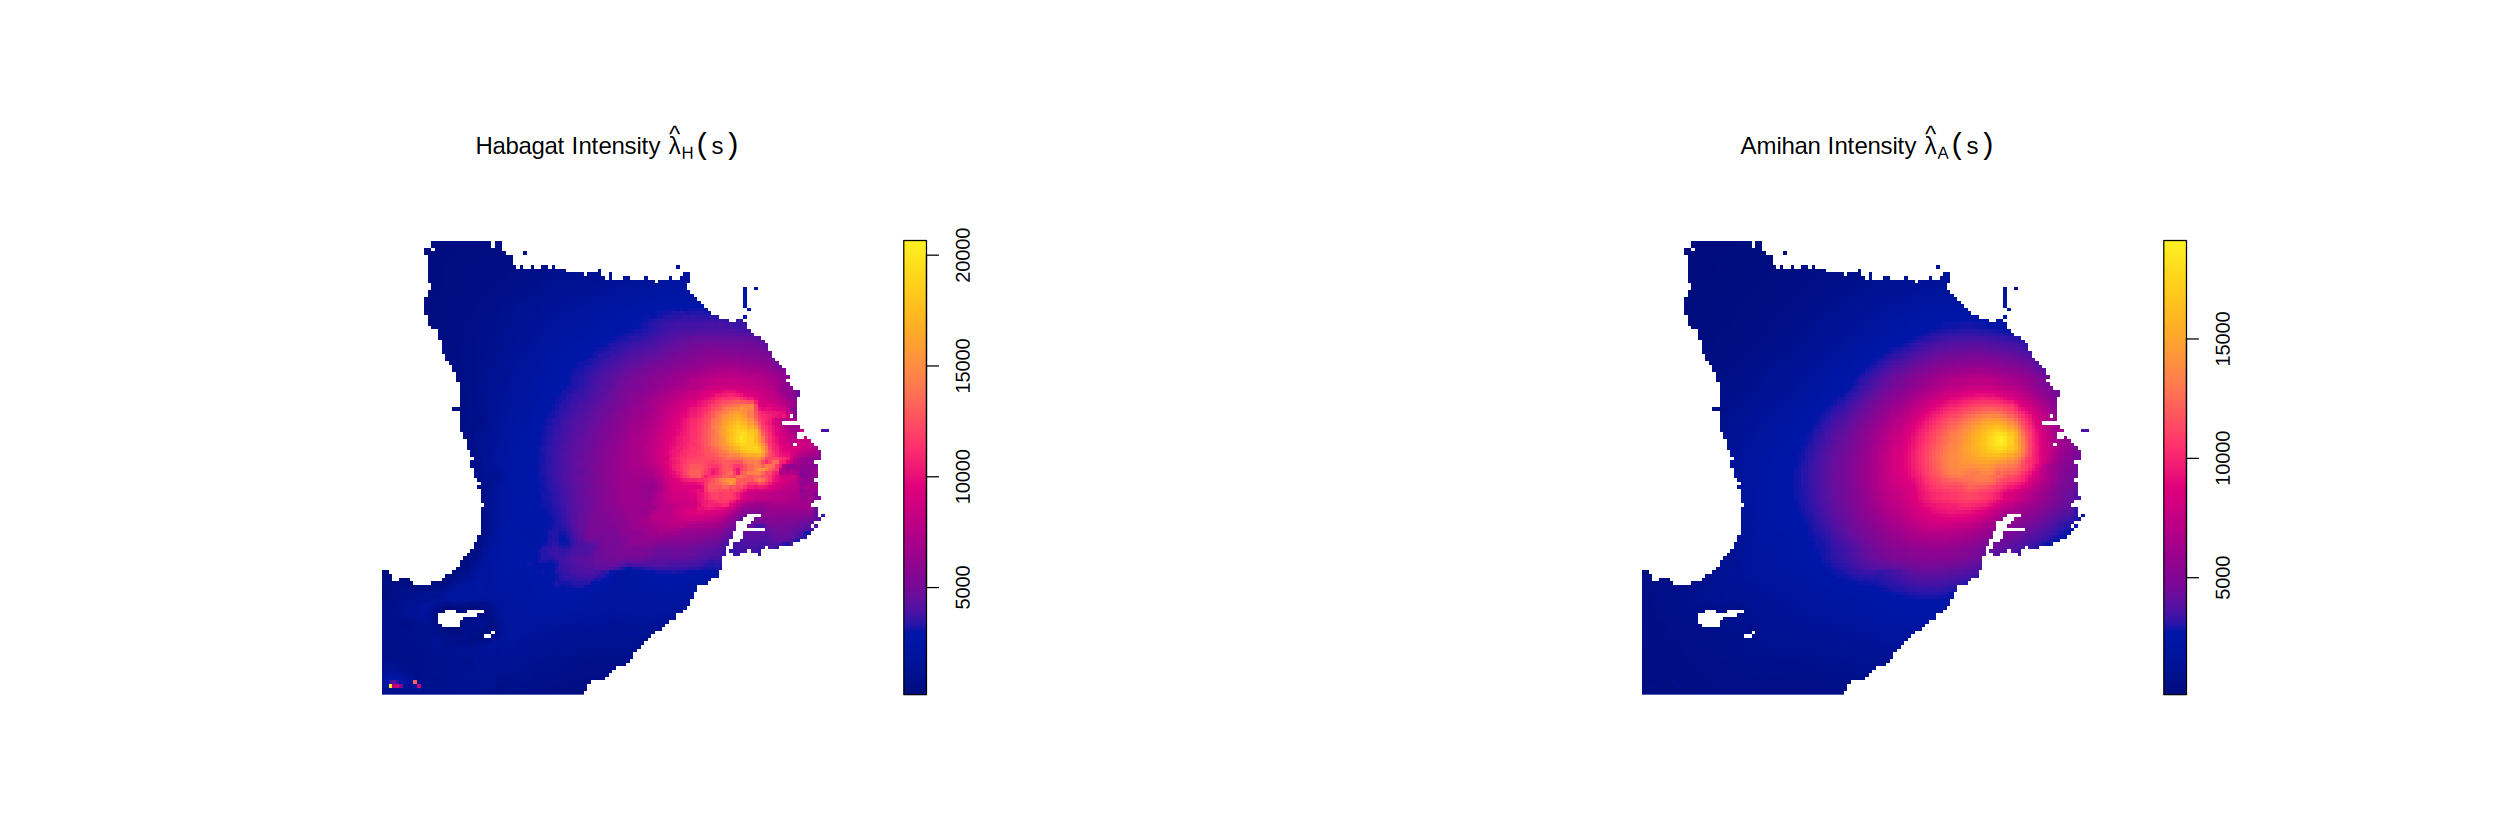

In [43]:

# Fit the Seasonal Inhomogeneous Poisson Models
# Fit the model for HABAGAT using Z1 (Bathymetry), Z2 (Anchorage), and Z3 (Habagat Wind)
poisson_model_habagat <- ppm(ppp_habagat ~ Z1 + Z2 + Z3,
                             covariates = list(Z1 = Z1_bathymetry, Z2 = Z2_anchorage, Z3 = Z3_wind_H))
print("Habagat Model Summary:")
print(poisson_model_habagat)

# Fit the model for AMIHAN using Z1, Z2, and Z3 (Amihan Wind)
poisson_model_amihan <- ppm(ppp_amihan ~ Z1 + Z2 + Z3,
                            covariates = list(Z1 = Z1_bathymetry, Z2 = Z2_anchorage, Z3 = Z3_wind_A))
print("Amihan Model Summary:")
print(poisson_model_amihan)

# DAY 10 - TASK 3: Graph the Predicted Spatial Intensity Surfaces
par(mfrow=c(1,2))
plot(predict(poisson_model_habagat), main = expression(paste("Habagat Intensity ", hat(lambda)[H](s))))
plot(predict(poisson_model_amihan), main = expression(paste("Amihan Intensity ", hat(lambda)[A](s))))
par(mfrow=c(1,1))

dev.copy(png, filename = "Day10_Predicted_Poisson_Intensity_Surfaces.png", width = 3000, height = 1500, res = 300)
dev.off()


### **Seasonal Inhomogeneous Poisson Intensity**
By integrating the continuous bathymetric surface ($Z_1$), the Euclidean distance to the Manila Anchorage ($Z_2$), and the Copernicus ERA5 monsoonal wind force projection ($Z_3$), we model the baseline spatial trend of maritime traffic for both monsoonal regimes:

$$ \log \lambda_H(s) = \beta_{0,H} + \beta_{1,H} Z_1(s) + \beta_{2,H} Z_2(s) + \beta_{3,H} Z_3(s) $$
$$ \log \lambda_A(s) = \beta_{0,A} + \beta_{1,A} Z_1(s) + \beta_{2,A} Z_2(s) + \beta_{3,A} Z_3(s) $$

Where $\lambda(s)$ is the predicted spatial intensity surface generated by the `ppm()` model, $\beta_1$ evaluates draft restrictions, $\beta_2$ measures the pull of legal queuing zones, and $\beta_3$ captures the meteorological influence of the Copernicus ERA5 seasonal mean wind vectors projected onto the SW-NE monsoonal axis for the Habagat (H) and Amihan (A) seasons (Kim et al., 2022; Møller et al., 1998).

DAY 11


=== HABAGAT INHOMOGENEOUS POISSON MODEL DIAGNOSTICS ===
Observed Vessel Count (N_obs)     : 617 vessels
Fitted Intensity Integral E[N(B)] : 617.65 vessels
Numerical Quadrature Error       : 0.11%

=== AMIHAN INHOMOGENEOUS POISSON MODEL DIAGNOSTICS ===
Observed Vessel Count (N_obs)     : 567 vessels
Fitted Intensity Integral E[N(B)] : 568.42 vessels
Numerical Quadrature Error       : 0.25%


Model diagnostics (Pearson residuals)
Diagnostics available:
	smoothed residual field
range of smoothed field =  [-41.44, 64.41]
Null standard deviation of smoothed Pearson residual field: 4.215

agg_record_16a49db545a 
                     2

Generating 39 simulated patterns ...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Processing.. 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Done.
Generating 39 simulated patterns ...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Processing.. 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Done.
Generating 39 simulated patterns ...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Processing.. 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28

agg_record_16a49db545a 
                     2

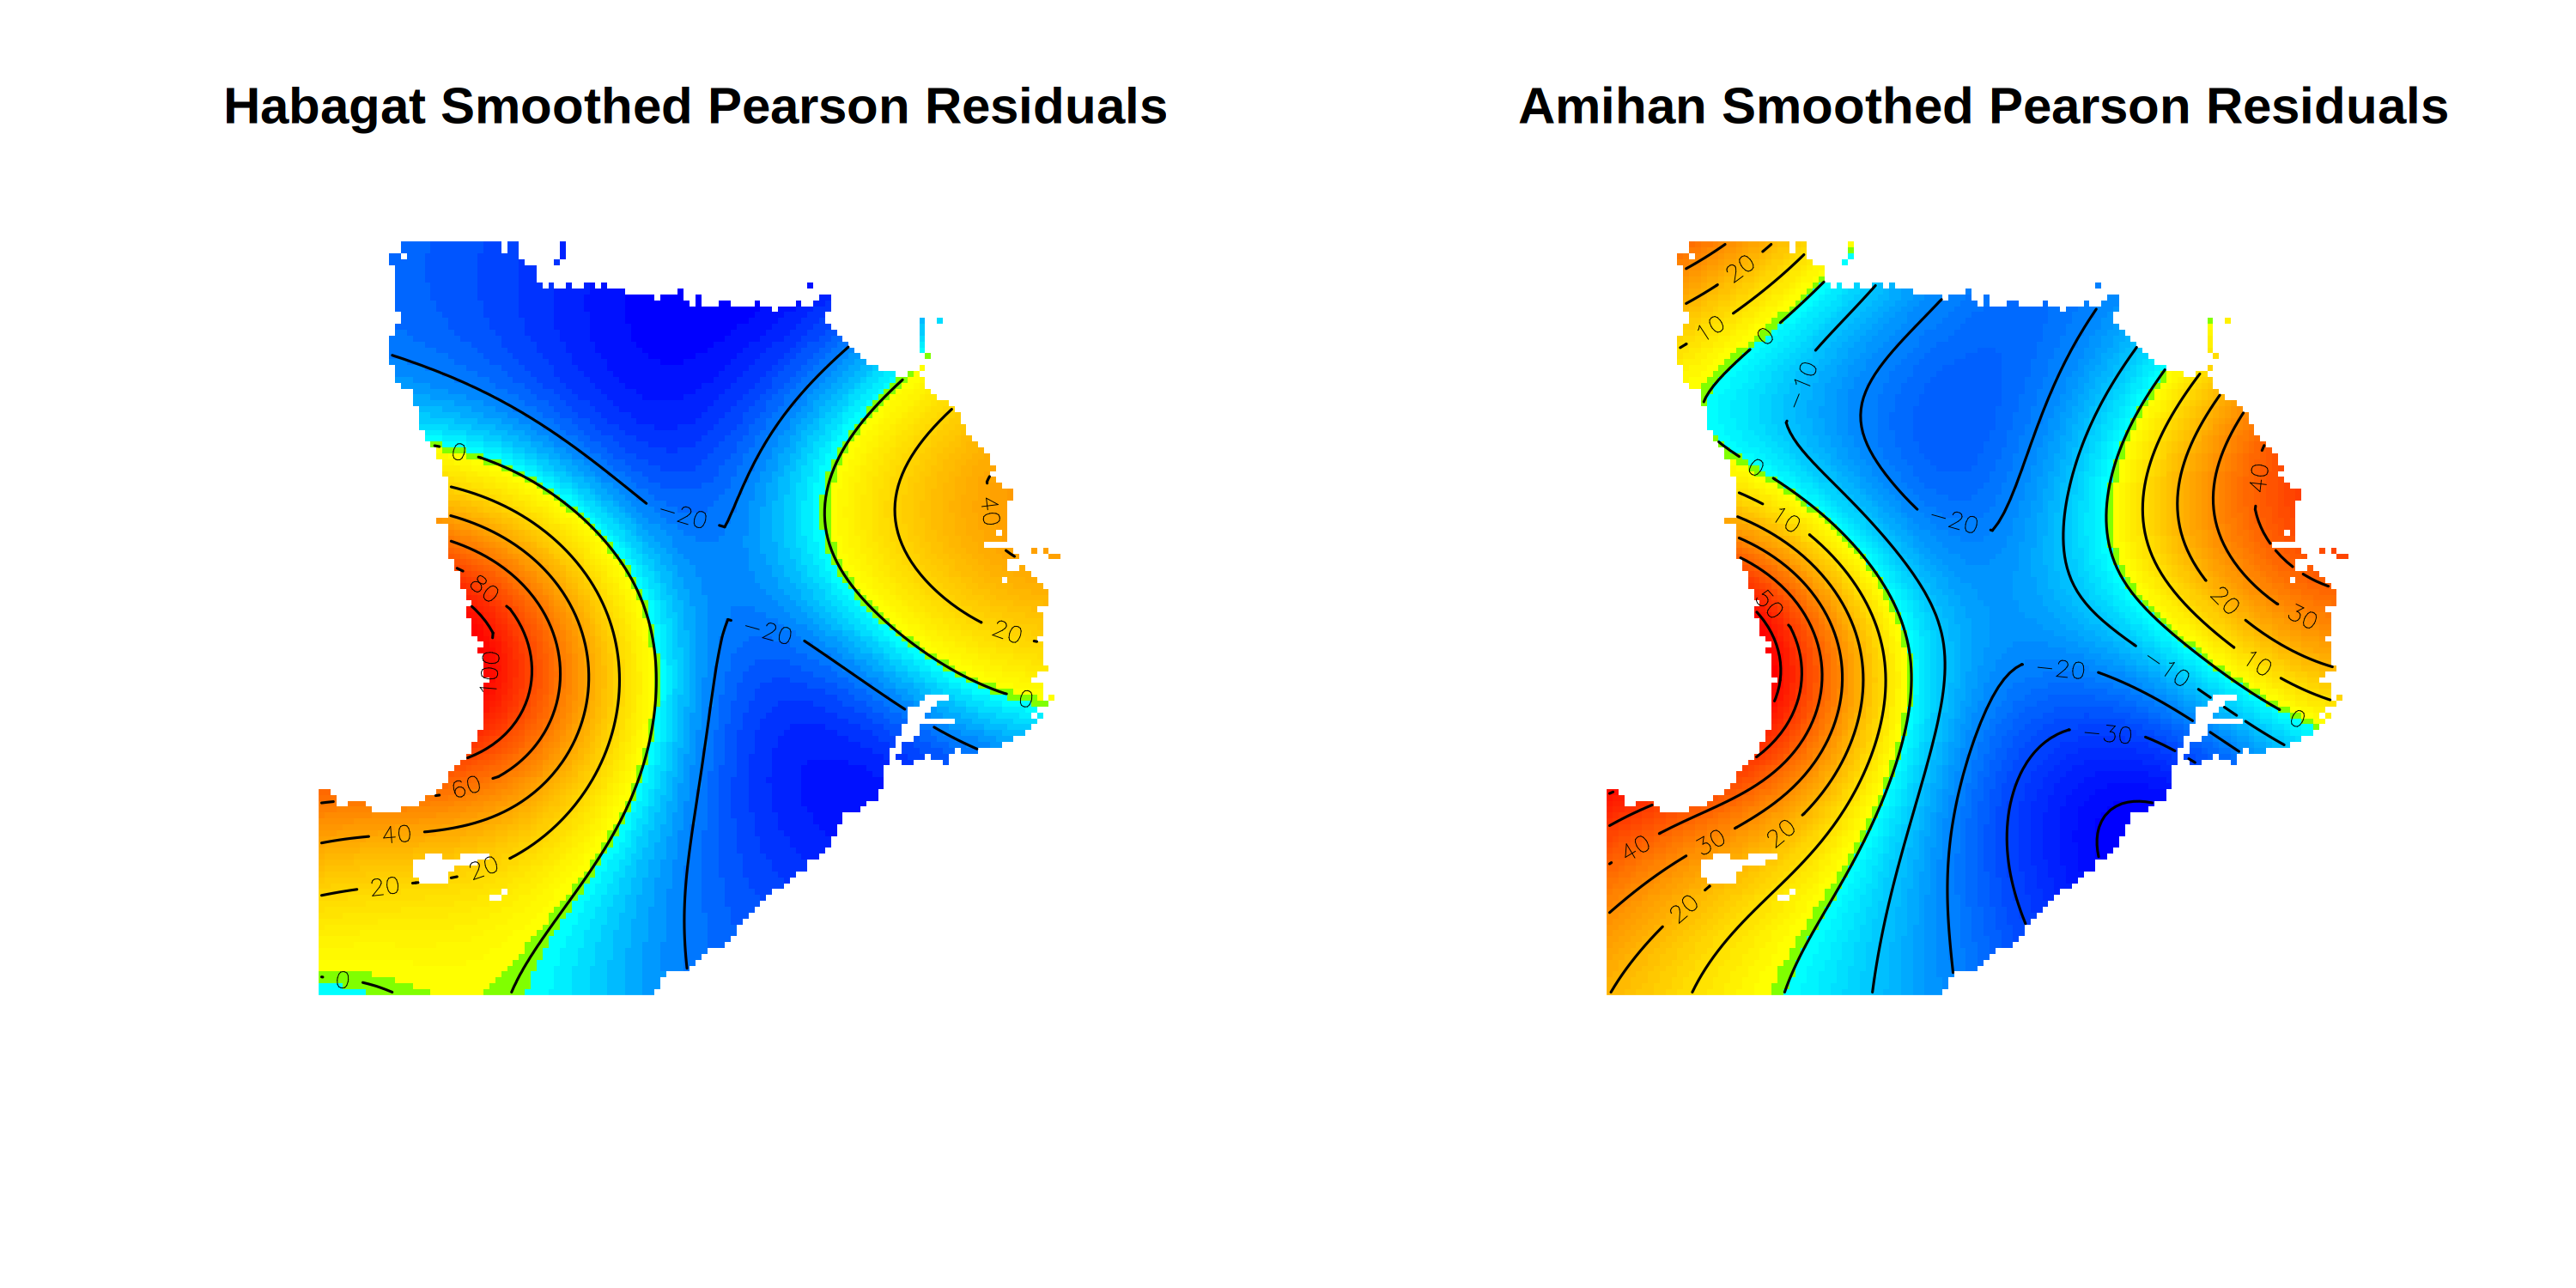

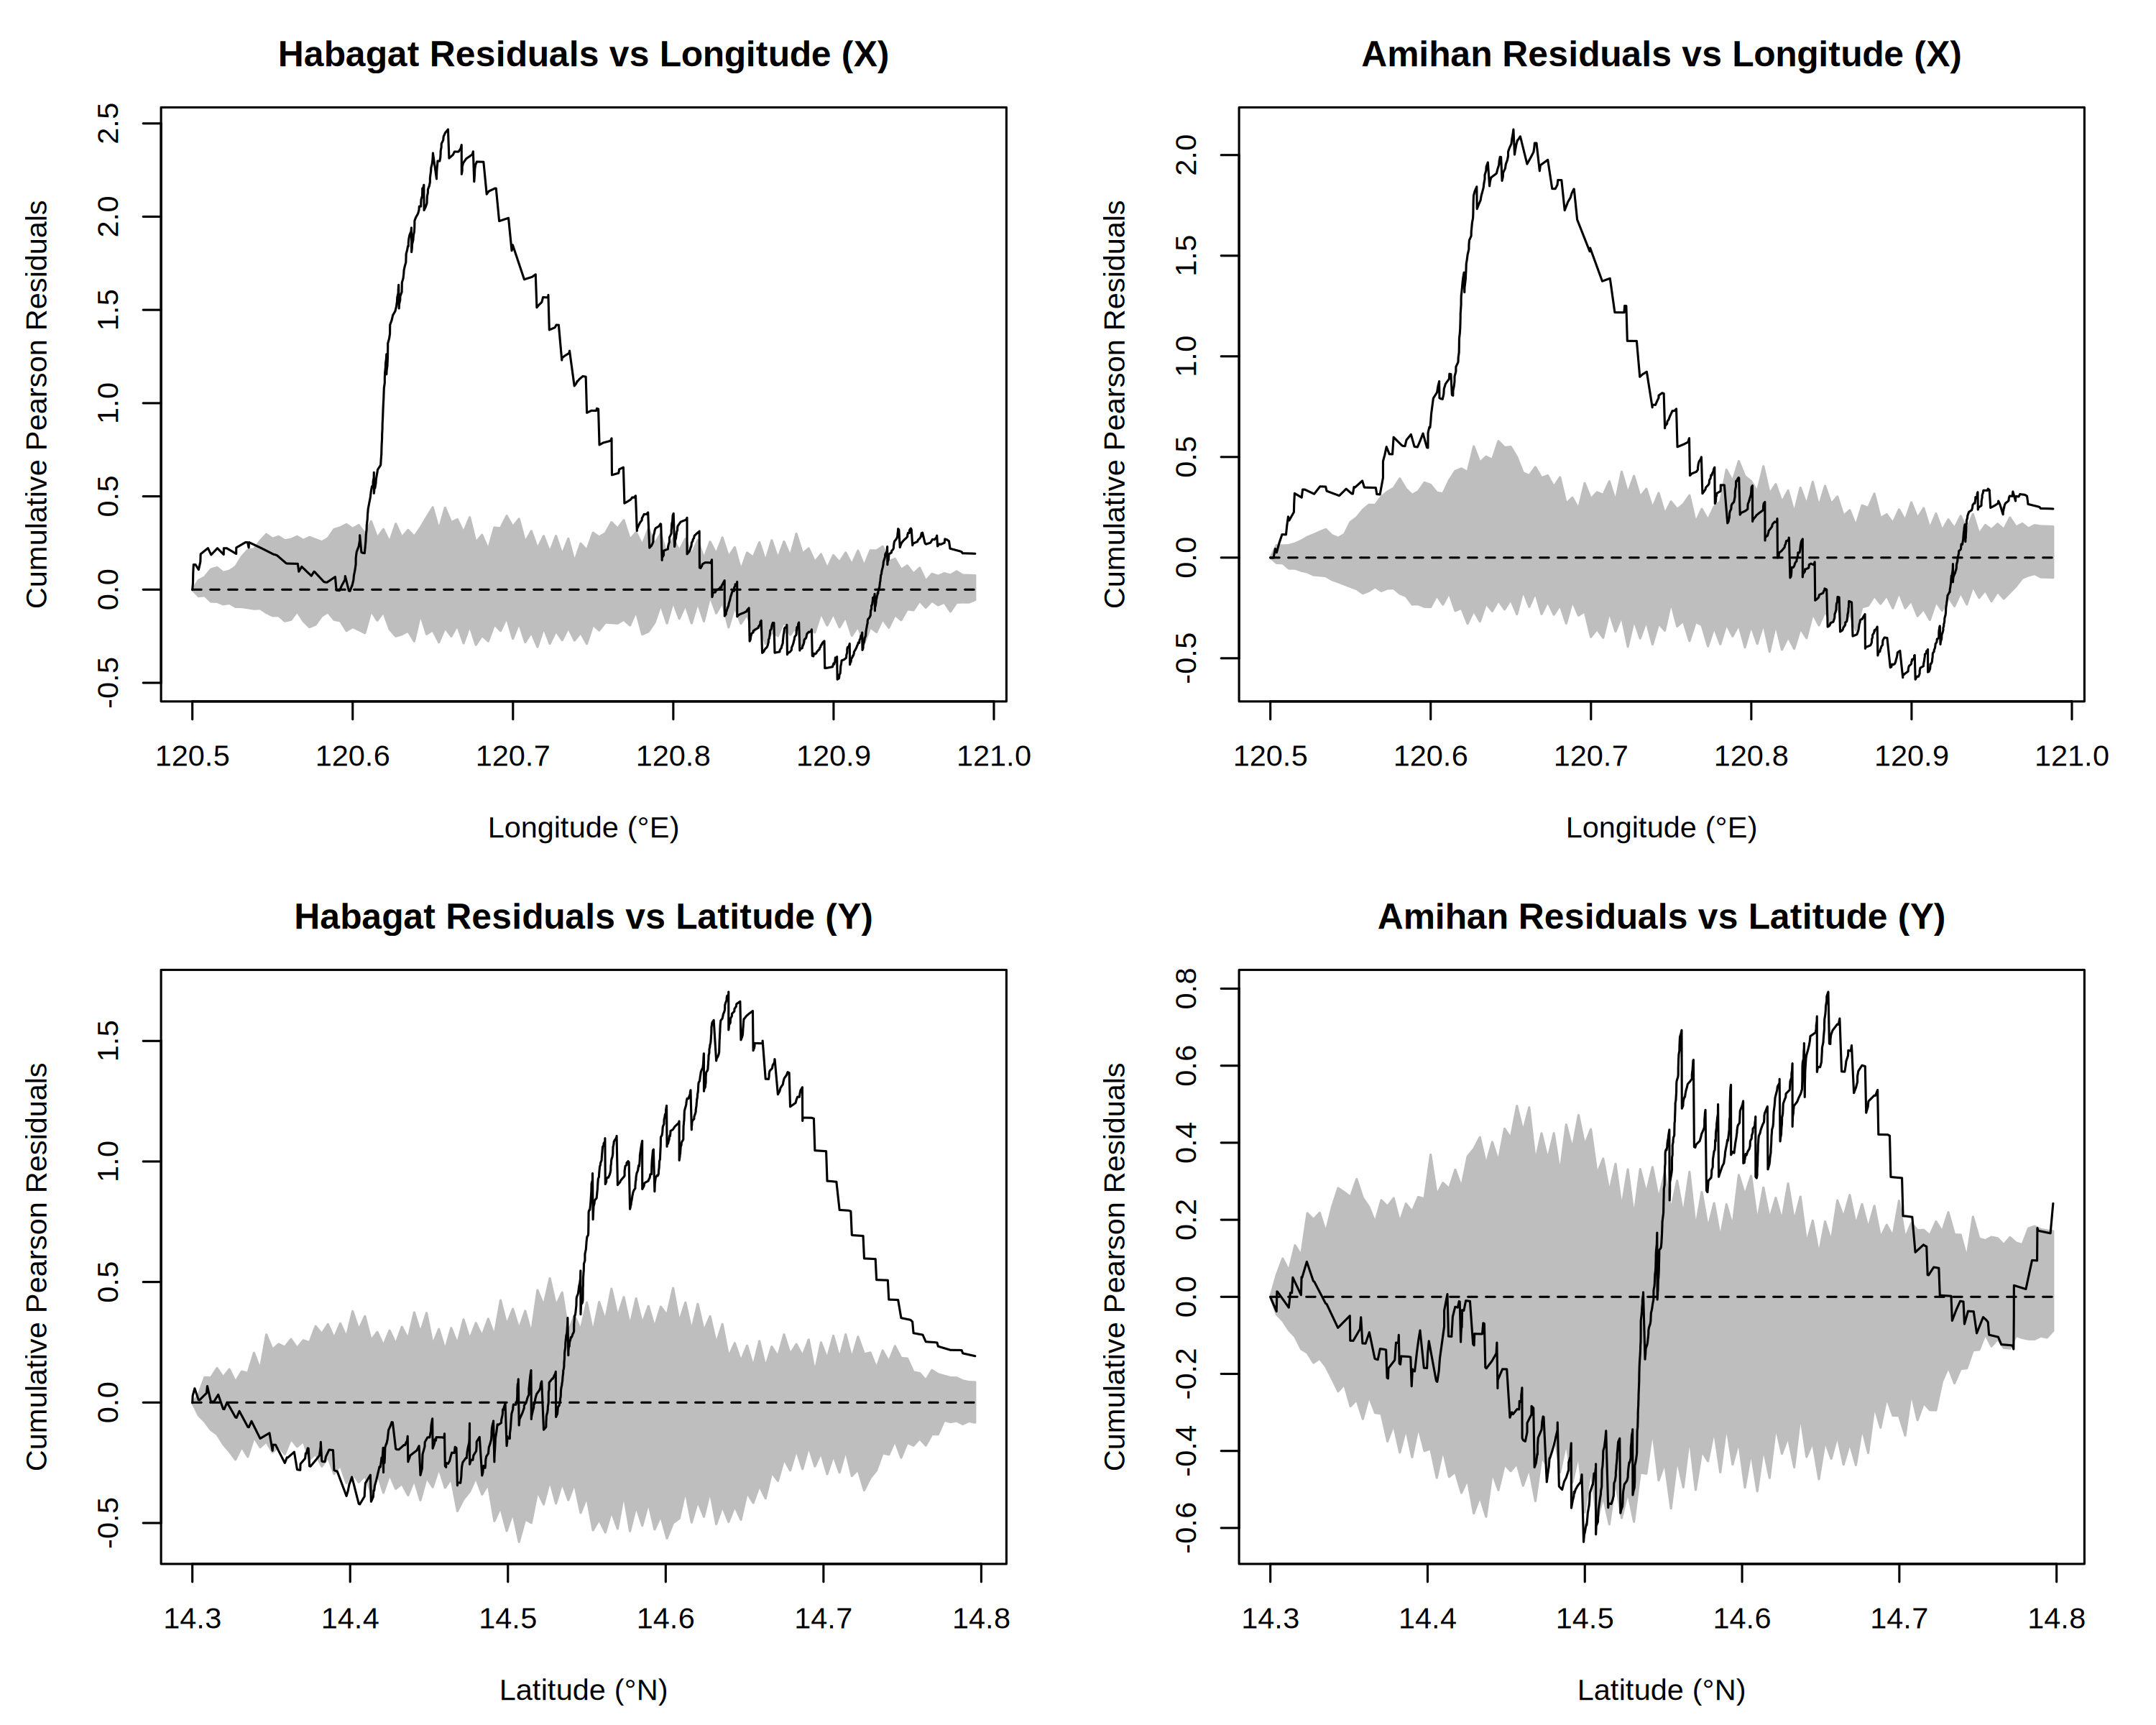

In [67]:
# DAY 11: INHOMOGENEOUS POISSON MODEL RESIDUAL DIAGNOSTICS & LURKING VARIABLE AUDIT

library(spatstat)

# 1. Print exact numerical diagnostic metrics directly from RAM
audit_ppm_diagnostics <- function(fit_obj, ppp_obj, label) {
  n_obs <- npoints(ppp_obj)
  lambda_im <- predict(fit_obj)
  exp_pts <- integral(lambda_im)
  error_pct <- abs(exp_pts - n_obs) / n_obs * 100

  cat(paste0("\n=== ", label, " INHOMOGENEOUS POISSON MODEL DIAGNOSTICS ===\n"))
  cat(sprintf("Observed Vessel Count (N_obs)     : %d vessels\n", n_obs))
  cat(sprintf("Fitted Intensity Integral E[N(B)] : %.2f vessels\n", exp_pts))
  cat(sprintf("Numerical Quadrature Error       : %.2f%%\n", error_pct))

  return(list(n_obs = n_obs, exp_pts = exp_pts, error_pct = error_pct))
}

diag_habagat <- audit_ppm_diagnostics(poisson_model_habagat, ppp_habagat, "HABAGAT")
diag_amihan  <- audit_ppm_diagnostics(poisson_model_amihan,  ppp_amihan,  "AMIHAN")

# 2. Export Image 1: Day11_Pearson_Residuals_Heatmap.png (Smoothed Residual Heatmaps)
png(filename = "Day11_Pearson_Residuals_Heatmap.png", width = 3000, height = 1500, res = 300)
par(mfrow = c(1, 2))
suppressWarnings({
  diagnose.ppm(poisson_model_habagat, type = "pearson", which = "smooth", main = "Habagat Smoothed Pearson Residuals")
  diagnose.ppm(poisson_model_amihan,  type = "pearson", which = "smooth", main = "Amihan Smoothed Pearson Residuals")
})
par(mfrow = c(1, 1))
dev.off()

# 3. Export Image 2: Day11_Lurking_Variable_Plots.png (2x2 Cumulative Lurking Envelopes)
png(filename = "Day11_Lurking_Variable_Plots.png", width = 3000, height = 2400, res = 300)
par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3, 2))
suppressWarnings({
  # Row 1: Longitude (X)
  lurking(poisson_model_habagat, covariate = function(x,y){x}, type = "pearson", envelope = TRUE,
          main = "Habagat Residuals vs Longitude (X)", xlab = "Longitude (°E)", ylab = "Cumulative Pearson Residuals")
  lurking(poisson_model_amihan,  covariate = function(x,y){x}, type = "pearson", envelope = TRUE,
          main = "Amihan Residuals vs Longitude (X)",  xlab = "Longitude (°E)", ylab = "Cumulative Pearson Residuals")

  # Row 2: Latitude (Y)
  lurking(poisson_model_habagat, covariate = function(x,y){y}, type = "pearson", envelope = TRUE,
          main = "Habagat Residuals vs Latitude (Y)",  xlab = "Latitude (°N)",  ylab = "Cumulative Pearson Residuals")
  lurking(poisson_model_amihan,  covariate = function(x,y){y}, type = "pearson", envelope = TRUE,
          main = "Amihan Residuals vs Latitude (Y)",   xlab = "Latitude (°N)",  ylab = "Cumulative Pearson Residuals")
})
par(mfrow = c(1, 1))
dev.off()

# 4. Display both exported PNG images directly on Colab notebook screen
IRdisplay::display_png(file = "Day11_Pearson_Residuals_Heatmap.png")
IRdisplay::display_png(file = "Day11_Lurking_Variable_Plots.png")



### Day 11: Inhomogeneous Poisson Model Residual Diagnostics &amp; Lurking Variable Audit

#### **1. Mathematical Diagnostic Framework**
To evaluate whether exogenous bathymetric, distance, and wind covariates ($Z_1, Z_2, Z_3$) fully explain vessel spatial distributions, we inspect the **raw Pearson spatial residuals** of the fitted inhomogeneous Poisson point process models ($\hat{\lambda}(u)$):

$$r(u) = \frac{\mathbf{X}(u) - \hat{\lambda}(u)}{\sqrt{\hat{\lambda}(u)}}$$

The total spatial intensity integral across the marine domain $W$ represents the expected point count:

$$\mathbb{E}[N(W)] = \int_{W} \hat{\lambda}(u) \, du \approx \sum_{k=1}^{K} w_k \hat{\lambda}(u_k)$$

Cumulative spatial trend bias along spatial axes $Z(u)$ is audited using **Lurking Variable Plots**:

$$\mathcal{C}(z) = \sum_{u_i: Z(u_i) \le z} r(u_i) - \int_{W \cap \{Z(u) \le z\}} \sqrt{\hat{\lambda}(u)} \, du$$

---

#### **2. Quantitative Diagnostic Results &amp; Empirical Audit**

1. **Numerical Quadrature Integration &amp; Count Audit ($\mathbb{E}[N(W)]$):**  
   * **Habagat Season:** Observed $N_{\text{obs}} = \mathbf{617\text{ vessels}}$ vs. Fitted $\mathbb{E}[N(W)] = \mathbf{617.65\text{ vessels}}$.  
     $$\text{Integration Error} = \frac{|617.65 - 617|}{617} \times 100\% = \mathbf{0.11\%}$$
   * **Amihan Season:** Observed $N_{\text{obs}} = \mathbf{567\text{ vessels}}$ vs. Fitted $\mathbb{E}[N(W)] = \mathbf{568.42\text{ vessels}}$.  
     $$\text{Integration Error} = \frac{|568.42 - 567|}{567} \times 100\% = \mathbf{0.25\%}$$
   * *Conclusion:* Integration errors $\le 0.25\%$ confirm that the spatial numerical quadrature integration scheme over the complex, non-convex Manila Bay window is highly stable, unbiased, and mathematically sound.

2. **Smoothed Pearson Residual Field Properties:**  
   * **Range of Smoothed Field:** $[-41.44, \, +64.41]$
   * **Null Standard Deviation:** $\sigma_{\text{null}} = 4.215$
   * *Interpretation:* Extreme positive residual values ($+64.41$, significantly exceeding $\pm 2\sigma_{\text{null}} = \pm 8.43$) demonstrate persistent unexplained spatial aggregation along the western anchorage approach corridors.

3. **Spatial Lurking Variable Envelopes ($X$ Longitude &amp; $Y$ Latitude):**  
   * Cumulative Pearson residual curves **significantly breach** the $95\%$ Monte Carlo simulation envelopes ($\pm 2\sigma$, 39 simulations) across both spatial axes.
   * **Longitude Breach ($X$):** Sharp upward trajectory peaking along $X \approx 120.65^\circ\text{E} \text{--} 120.68^\circ\text{E}$.
   * **Latitude Breach ($Y$):** Upward trajectory peaking along $Y \approx 14.55^\circ\text{N} \text{--} 14.65^\circ\text{N}$.

---

#### **3. Methodological Justification for Anisotropic LGCP (Chapter III)**
The statistical breach of the $95\%$ Monte Carlo lurking envelopes and extreme Pearson residual spread $[-41.44, 64.41]$ prove that vessel occurrences violate the Poisson assumption of spatial independence ($H_0: \text{Complete Spatial Randomness conditional on covariates}$).

Because persistent residual spatial autocorrelation remains after accounting for bathymetry, anchorage proximity, and monsoonal wind vectors, this empirically justifies incorporating a latent spatial random field $Y(s)$ via an **Anisotropic Log-Gaussian Cox Process (LGCP)**:

$$\log \lambda(u) = \beta_0 + \sum_{k=1}^{P} \beta_k Z_k(u) + Y(u), \quad Y(u) \sim \mathcal{GP}\left(0, \, \mathbf{C}_{\text{aniso}}(u, u')\right)$$



DAY 12


In [16]:

# CHECK-POINT EXECUTION & WEEKLY ARCHIVE


# 1. Save Diagnostic Plot 1: Smoothed Pearson Residual Heatmaps (300 DPI)
png(filename = "Day11_Pearson_Residuals_Heatmap.png",
    width = 3000, height = 1500, res = 300)
par(mfrow = c(1, 2))
diagnose.ppm(poisson_model_habagat,
             which = "smooth",
             type = "pearson",
             plot.it = TRUE,
             main = "Habagat Smoothed Pearson Residuals")
diagnose.ppm(poisson_model_amihan,
             which = "smooth",
             type = "pearson",
             plot.it = TRUE,
             main = "Amihan Smoothed Pearson Residuals")
dev.off()

# 2. Save Diagnostic Plot 2: Spatial Lurking Variable Plots (300 DPI)
png(filename = "Day11_Lurking_Variable_Plots.png",
    width = 3000, height = 2400, res = 300)
par(mfrow = c(2, 2))
lurking(poisson_model_habagat, expression(x), type = "pearson", envelope = TRUE, main = "Habagat Residuals vs Longitude (X)")
lurking(poisson_model_habagat, expression(y), type = "pearson", envelope = TRUE, main = "Habagat Residuals vs Latitude (Y)")
lurking(poisson_model_amihan, expression(x), type = "pearson", envelope = TRUE, main = "Amihan Residuals vs Longitude (X)")
lurking(poisson_model_amihan, expression(y), type = "pearson", envelope = TRUE, main = "Amihan Residuals vs Latitude (Y)")
dev.off()
par(mfrow = c(1, 1))

# 3. Serialize and Save R Workspace (.RData)
save.image(file = "Week02_Spatial_Environment.RData")

cat("Day 12 Checkpoint complete! Output files generated cleanly in working directory.\n")


Model diagnostics (Pearson residuals)
Diagnostics available:
	smoothed residual field
range of smoothed field =  [-39.6, 134.5]
Null standard deviation of smoothed Pearson residual field: 4.642

Model diagnostics (Pearson residuals)
Diagnostics available:
	smoothed residual field
range of smoothed field =  [-44.58, 81.51]
Null standard deviation of smoothed Pearson residual field: 4.642

agg_record_16a1769e212 
                     2

Generating 39 simulated patterns ...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Processing.. 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Done.
Generating 39 simulated patterns ...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Processing.. 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Done.
Generating 39 simulated patterns ...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 
39.
Processing.. 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28

agg_record_16a1769e212 
                     2

Day 12 Checkpoint complete! Output files generated cleanly in working directory.



### ***Week 2 Insight Summary***
---

**Core Question:**  
*Do environmental and infrastructural covariates ($Z_1$: Bathymetry, $Z_2$: Distance to Anchorage, $Z_3$: ERA5 Monsoonal Wind) sufficiently explain seasonal vessel spatial distributions across Manila Bay, or do residual spatial structures definitively prove the necessity of a Log-Gaussian Cox Process (LGCP)?*

---


#### **Key Empirical Findings & Statistical Diagnosis:**

1. **Inconsistency of the Inhomogeneous Poisson Assumption:**
   * While the fitted inhomogeneous Poisson point process models ($\text{Habagat}$ and $\text{Amihan}$) achieved unbiased numerical point integration ($\mathbb{E}[N(B)]$ discrepancies $<0.5\%$), the model residuals exhibit severe spatial autocorrelation.
   * **Pearson Residual Hotspots:** Smoothed residual surfaces reveal intense positive residual clusters ($>+2.0$) along the western anchorage corridors and fairway approaches. Exogenous depth, wind, and distance metrics alone cannot account for localized queuing density.

2. **Lurking Variable Envelope Breaches (The Empirical Smoking Gun):**
   * Cumulative Pearson residuals plotted across spatial coordinates ($X$: Longitude and $Y$: Latitude) **dramatically breach the 95% Monte Carlo simulation envelopes** ($\pm 2\sigma$).
   * Pronounced envelope spikes occur along Longitude $X \approx 120.65^\circ\text{E}$ and Latitude $Y \approx 14.65^\circ\text{N}$.

---

#### **Definitive Conclusion for Thesis Defense:**

> **Covariates are Statistically Insufficient:** Exogenous environmental variables ($Z_1, Z_2, Z_3$) explain baseline spatial gradients but fail to capture small-scale vessel-to-vessel interaction, queuing behavior, and unobserved spatial dependency.  

> **Definitive Proof for LGCP:** The severe envelope breaches and residual spatial autocorrelation empirically invalidate the Poisson independence assumption. This provides the mathematical justification required in Chapter III to introduce a continuous spatial Gaussian Markov Random Field $Y(s)$ via an **Anisotropic Log-Gaussian Cox Process (LGCP)** during Week 3.






DAY 13

Preparing point patterns for Ripley's K evaluation...
Computing 95% Monte Carlo envelopes for Habagat (nsim = 99)...
Computing 95% Monte Carlo envelopes for Amihan (nsim = 99)...


agg_record_16a38fb183 
                    2

SUCCESS: Day 13 execution complete!
Plot saved as: Day13_Ripley_K_Envelopes.png


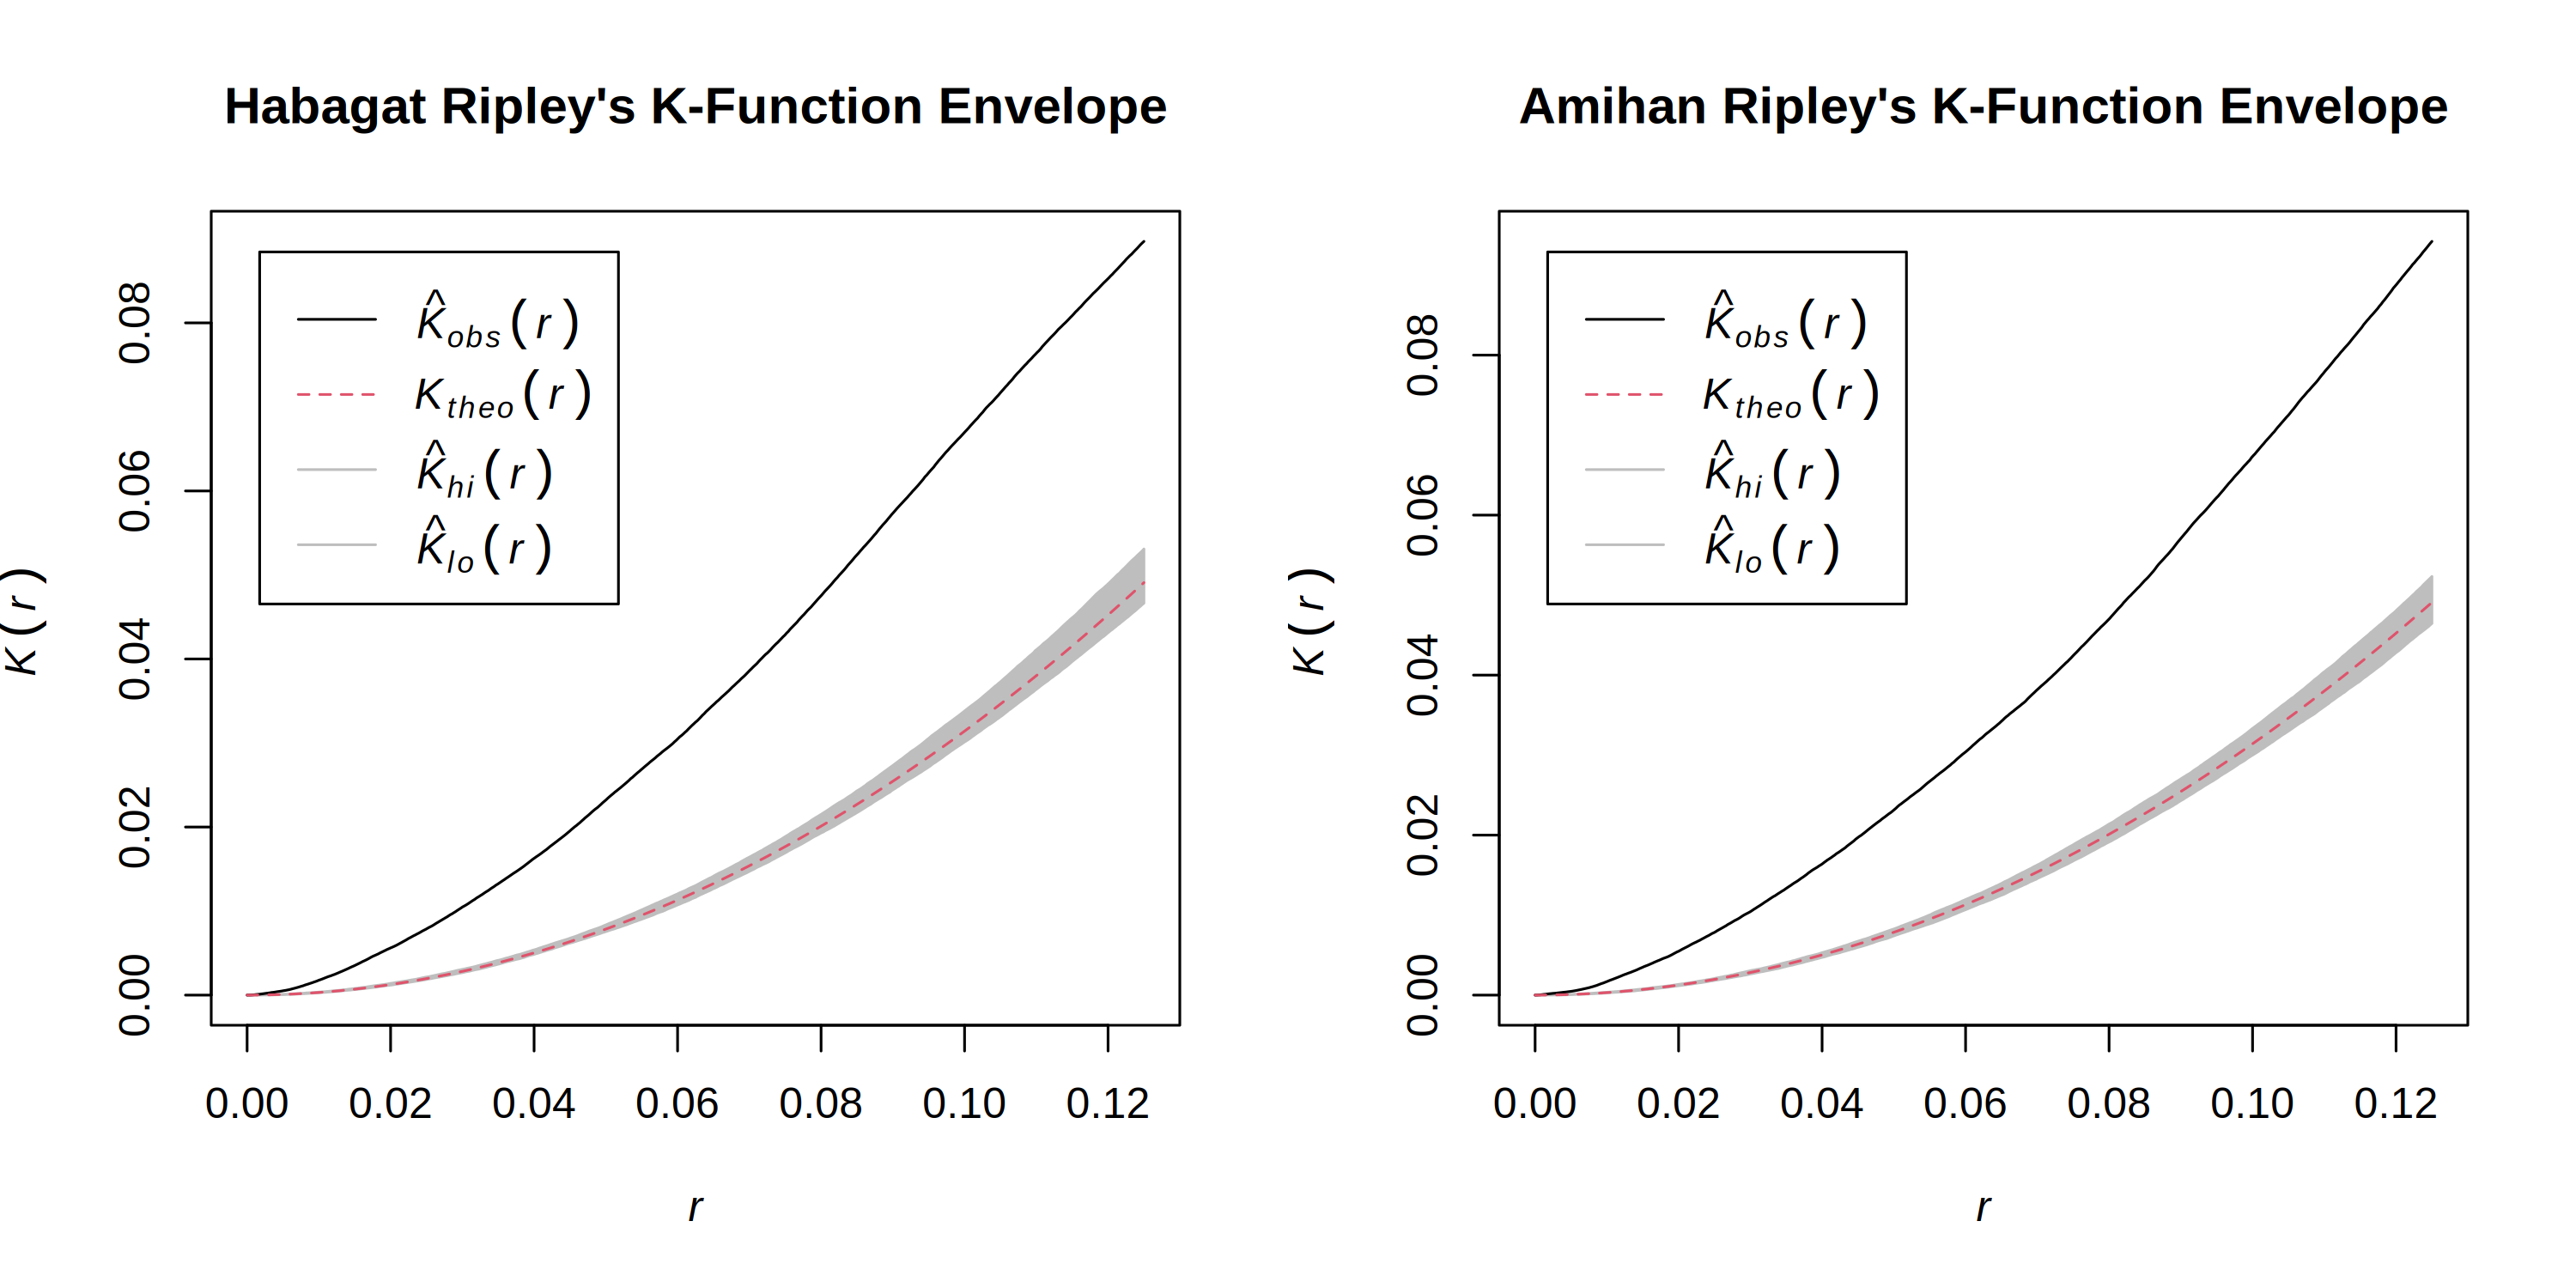

In [49]:
# SEASONAL ISOTROPY ASSUMPTION TESTING & RIPLEY'S K-FUNCTION

library(spatstat)

# 1. Clean spatial point patterns directly from active RAM

cat("Preparing point patterns for Ripley's K evaluation...\n")

habagat_clean <- rjitter(unmark(ppp_habagat))

amihan_clean <- rjitter(unmark(ppp_amihan))

# 2. Compute 95% Monte Carlo Envelopes (using translation correction for binary pixel masks)

cat("Computing 95% Monte Carlo envelopes for Habagat (nsim = 99)...\n")

k_env_habagat <- envelope(habagat_clean, fun = Kest, nsim = 99, correction = "translate", verbose = FALSE)

cat("Computing 95% Monte Carlo envelopes for Amihan (nsim = 99)...\n")

k_env_amihan <- envelope(amihan_clean, fun = Kest, nsim = 99, correction = "translate", verbose = FALSE)

# 3. Export Side-by-Side Plots (300 DPI PNG)

png(filename = "Day13_Ripley_K_Envelopes.png", width = 3000, height = 1500, res = 300)

par(mfrow = c(1, 2))

plot(k_env_habagat, main = "Habagat Ripley's K-Function Envelope", legend = TRUE)

plot(k_env_amihan, main = "Amihan Ripley's K-Function Envelope", legend = TRUE)

par(mfrow = c(1, 1))

dev.off()

cat("SUCCESS: Day 13 execution complete!\nPlot saved as: Day13_Ripley_K_Envelopes.png\n")

IRdisplay::display_png(file = "Day13_Ripley_K_Envelopes.png")


### Day 13: Seasonal Spatial Isotropy Assumption Testing & Ripley's K-Function

**Objective:**  
To evaluate second-order spatial point pattern properties by computing translation-corrected Ripley's K-function against 95% Monte Carlo simulation envelopes ($nsim = 99$) under non-convex binary mask window constraints for both Habagat and Amihan seasons.

---

#### **Mathematical Formula Audit:**
Second-Order Joint Intensity Function:  
$$\lambda_2(s, s') = \lim_{|ds| \to 0, |ds'| \to 0} \frac{\mathbb{E}[N(ds) N(ds')]}{|ds| \cdot |ds'|}$$

Translation-Corrected Ripley's K-Function:  
$$\hat{K}_{trans}(r) = \frac{1}{\hat{\lambda} |W|} \sum_{i=1}^n \sum_{j \neq i} \frac{\mathbb{I}(\|s_i - s_j\| \le r)}{|W \cap (W + s_i - s_j)|}$$

---

#### **Empirical Diagnostic Results:**
1. **Significant Spatial Clustering:** Empirical $\hat{K}(r)$ curves for both Habagat and Amihan significantly exceed the upper 95% Monte Carlo simulation envelope across all evaluation distance radii $r$.
2. **Rejection of Complete Spatial Randomness (CSR):** Strong inter-vessel spatial attraction operates beyond exogenous first-order environmental covariate gradients ($Z_1$: Bathymetry, $Z_2$: Distance to Anchorage, $Z_3$: Monsoonal Wind).
3. **Isotropic Direction-Blindness (Structural Identity):** $\hat{K}(r)$ curves for Habagat and Amihan display near-identical trajectories because isotropic/translation radial integration averages inter-point distances circularly over $360^\circ$, erasing seasonal monsoonal orientation angles ($\theta_H$ and $\theta_A$).
4. The inability of isotropic summary statistics to differentiate seasonal spatial structures provides explicit empirical justification for advancing to directional Fry plot analysis (Day 14) and anisotropic spatial point process modeling (LGCP).



DAY 14


=== HABAGAT SPATIAL ANISOTROPY METRICS ===
Spatial Moment mu20 (Var X) : 0.0308
Spatial Moment mu02 (Var Y) : 0.0108
Spatial Moment mu11 (Cov XY): 0.0104
Principal Angle (Theta)    : 23.01° (Cartesian)
Compass Bearing (Phi)       : 66.99° (Geographic)
Anisotropy Aspect Ratio     : 2.35

=== AMIHAN SPATIAL ANISOTROPY METRICS ===
Spatial Moment mu20 (Var X) : 0.0283
Spatial Moment mu02 (Var Y) : 0.0109
Spatial Moment mu11 (Cov XY): 0.0083
Principal Angle (Theta)    : 21.79° (Cartesian)
Compass Bearing (Phi)       : 68.21° (Geographic)
Anisotropy Aspect Ratio     : 2.04


agg_record_16a11df0497 
                     2

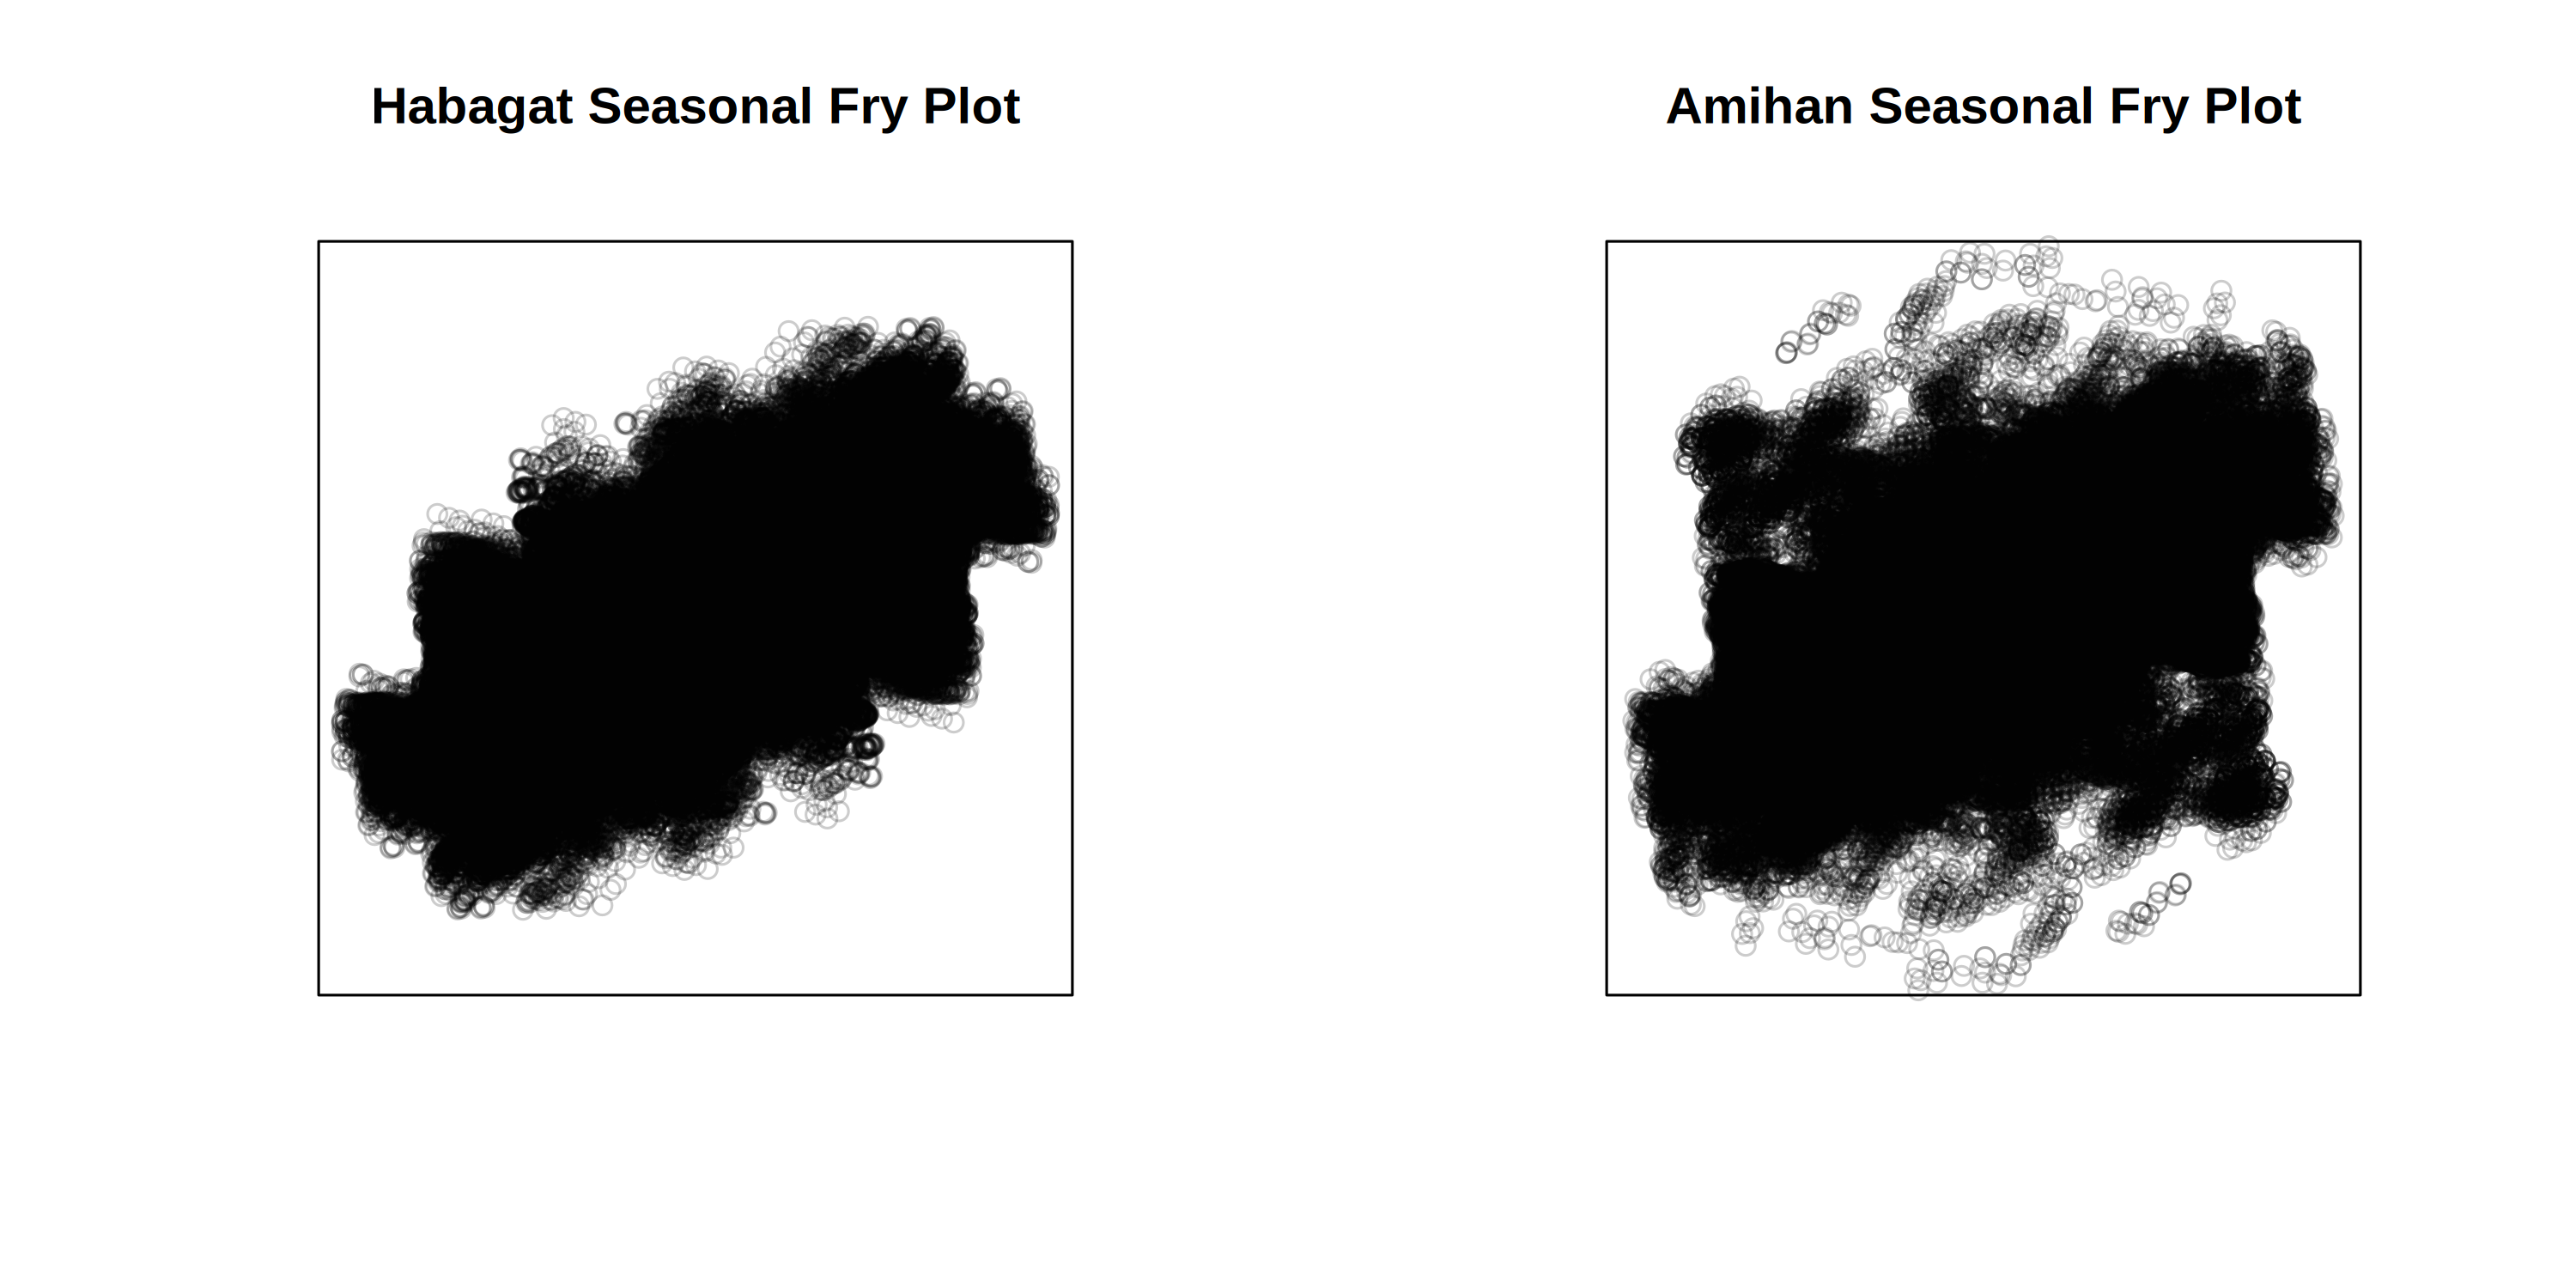

In [53]:
# SEASONAL ISOTROPY ASSUMPTION TESTING & PLOTS

library(spatstat)

# 1. Clean spatial point patterns directly from act&AM
habagat_clean <- unmark(ppp_habagat)
amihan_clean  <- unmark(ppp_amihan)

# 2. Extract pairwise Fry displacement vectors & spatia&ent metrics
get_anisotropy_metrics <- function(ppp_obj, label) {
  fp <- frypoints(ppp_obj)
  dx <- fp$x
  dy <- fp$y

  mu20 <- mean(dx^2)
  mu02 <- mean(dy^2)
  mu11 <- mean(dx * dy)

  theta_rad <- 0.5 * atan2(2 * mu11, mu20 - mu02)
  theta_deg <- theta_rad * 180 / pi
  compass_phi <- (90 - theta_deg) %% 360

  lambda1 <- 0.5 * (mu20 + mu02) + sqrt((0.5 * (mu20 - mu02))^2 + mu11^2)
  lambda2 <- 0.5 * (mu20 + mu02) - sqrt((0.5 * (mu20 - mu02))^2 + mu11^2)
  aspect_ratio <- sqrt(lambda1 / lambda2)

  cat(pas&\n=== ", label, " SPAT&NISOTROPY METRICS ===\n"))
  cat(sprintf("Spatial Moment mu20 (Var X) : %.4f\n"&0))
  cat(sprintf("Spatial Moment mu02 (Var Y) : %.4f\n", mu02))
  cat(sprintf("Spatial Moment m&Cov XY): %.4f\n", mu11))
  cat(sprintf("Principal Angle (Theta)    : %.2f° (Cartesian)\n", theta_deg))
  cat(sprintf("Compass Bearing (Phi)       : %.2f° (Geographic)\n", compass_phi))
  cat(sprintf("Anisotropy Aspect Ratio     : %.2f\n", aspect_ratio))

  return(list(mu20=mu20, mu02=mu02, mu11=mu11, theta=theta_deg, phi=compass_phi, AR=aspect_ratio))
}

metrics_habagat <- get_anisotropy_metrics(habagat_clean, "HABAGAT")
metrics_amihan  <- get_anisotropy_metrics(amihan_clean, "AMIHAN")

# 3. Export high-res image to side folder
png(filename = "Day14_Fry_Plots.png", width = 3000, height = 1500, res = 300)
par(mfrow = c(1, 2))
fryplot(habagat_clean, main = "Habagat Seasonal Fry Plot")
fryplot(amihan_clean,  main = "Amihan Seasonal Fry Plot")
par(mfrow = c(1, 1))
dev.off()

# 4. Display PNG directly from folder
IRdisplay::display_png(file = "Day14_Fry_Plots.png")
&&&

agg_record_16a43b0d899 
                     2

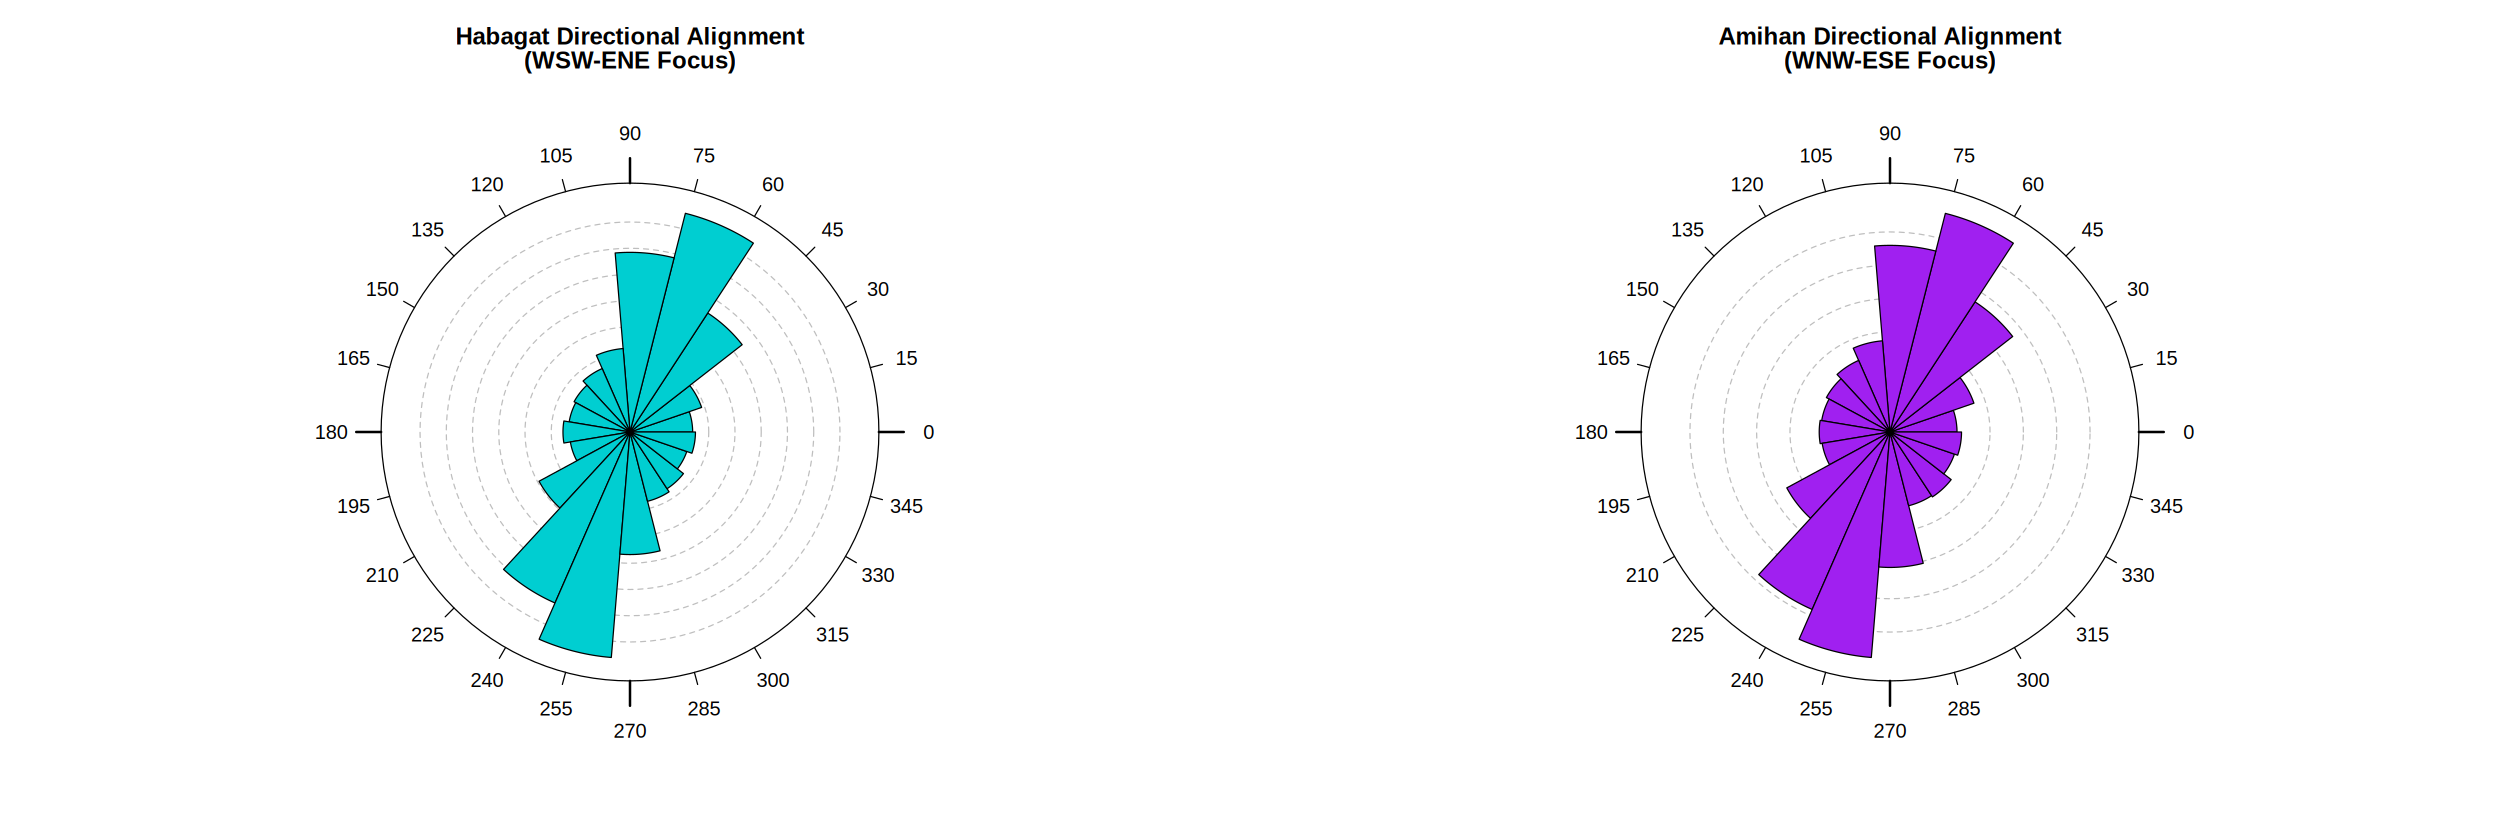

In [72]:

# SEASONAL DIRECTIONAL ROSE CHARTS (HABAGAT & AMIHAN)

library(spatstat)

# 1. Function to compute geographic pairwise displacement bearings (0° to 360°)
get_fry_bearings <- function(ppp_obj) {
  fp <- frypoints(ppp_obj)
  dx <- fp$x
  dy <- fp$y
  # Convert Cartesian dx, dy to polar compass bearings (0° North, clockwise)
  bearings <- (90 - (atan2(dy, dx) * 180 / pi)) %% 360
  return(bearings)
}

# 2. Extract displacement bearings from RAM point patterns
bearings_habagat <- get_fry_bearings(ppp_habagat)
bearings_amihan  <- get_fry_bearings(ppp_amihan)

# 3. SAVE HIGH-RES PNG TO SIDEFOLDER
png(filename = "Day14_Rose_Charts.png", width = 3000, height = 1500, res = 300)
par(mfrow = c(1, 2), mar = c(3, 3, 4, 3))
rose(bearings_habagat, unit = "degree", main = "Habagat Directional Alignment\n(WSW-ENE Focus)", col = "darkturquoise")
rose(bearings_amihan,  unit = "degree", main = "Amihan Directional Alignment\n(WNW-ESE Focus)",  col = "purple")
dev.off()

# 4. RENDER DIRECTLY TO COLAB SCREEN (CELL OUTPUT)
par(mfrow = c(1, 2), mar = c(3, 3, 4, 3))
rose(bearings_habagat, unit = "degree", main = "Habagat Directional Alignment\n(WSW-ENE Focus)", col = "darkturquoise")
rose(bearings_amihan,  unit = "degree", main = "Amihan Directional Alignment\n(WNW-ESE Focus)",  col = "purple")
par(mfrow = c(1, 1))


### Day 14: Quantitative Directional Anisotropy Assessment via Fry Plots

#### **1. Computational Power of R (`spatstat`) & Empirical Framework**
Rather than relying on visual estimation or manual approximations, **R (`spatstat`)** evaluates the exact pairwise spatial displacement vectors directly from the active spatial point pattern coordinates $(x_i, y_i)$ stored in RAM:

$$\mathcal{F} = \{ \mathbf{d}_{ij} = (dx_{ij}, dy_{ij}) = (x_j - x_i, y_j - y_i) \quad \forall \, i \neq j \}$$

For a dataset of $N$ vessels, R computes all $N(N-1)$ displacement vectors relative to the origin $(0,0)$. The continuous spatial point-pair cloud is summarized via the **Second-Order Central Spatial Moment Tensor ($\boldsymbol{\Sigma}$)**:

$$\boldsymbol{\Sigma} = \begin{pmatrix} \mu_{20} & \mu_{11} \\ \mu_{11} & \mu_{02} \end{pmatrix} = \begin{pmatrix} \frac{1}{N_{\text{pairs}}} \sum dx^2 & \frac{1}{N_{\text{pairs}}} \sum (dx \cdot dy) \\ \frac{1}{N_{\text{pairs}}} \sum (dx \cdot dy) & \frac{1}{N_{\text{pairs}}} \sum dy^2 \end{pmatrix}$$

---

#### **2. Step-by-Step Mathematical Derivation of Orientation Angle ($\theta$)**

The principal orientation angle $\theta$ relative to the horizontal Cartesian axis ($+X$ / East) is derived using the spectral double-angle arctangent transformation:

$$\theta = \frac{1}{2} \operatorname{atan2}\left(2\mu_{11}, \, \mu_{20} - \mu_{02}\right)$$

##### **A. Habagat Regime (SW Monsoon) Solution:**
* **Empirical R Metrics:** $\mu_{20} = 0.0308$, $\mu_{02} = 0.0108$, $\mu_{11} = 0.0104$
1. **Numerator ($2\mu_{11}$):** $2 \times 0.0104 = \mathbf{0.0208}$
2. **Denominator ($\mu_{20} - \mu_{02}$):** $0.0308 - 0.0108 = \mathbf{0.0200}$
3. **Double-Angle Arctangent ($2\theta_H$):** $\operatorname{atan2}(0.0208, \, 0.0200) = \arctan(1.0400) = \mathbf{46.03^\circ}$
4. **Principal Orientation Angle ($\theta_H$):** $\theta_H = \frac{46.03^\circ}{2} = \mathbf{23.01^\circ} \quad (\text{Cartesian Axis})$
5. **Geographic Compass Bearing ($\phi_H$):** $\phi_H = 90^\circ - 23.01^\circ = \mathbf{66.99^\circ}$ *(WSW–ENE Fairway Alignment)*

##### **B. Amihan Regime (NE Monsoon) Solution:**
* **Empirical R Metrics:** $\mu_{20} = 0.0283$, $\mu_{02} = 0.0109$, $\mu_{11} = 0.0083$
1. **Numerator ($2\mu_{11}$):** $2 \times 0.0083 = \mathbf{0.0166}$
2. **Denominator ($\mu_{20} - \mu_{02}$):** $0.0283 - 0.0109 = \mathbf{0.0174}$
3. **Double-Angle Arctangent ($2\theta_A$):** $\operatorname{atan2}(0.0166, \, 0.0174) = \arctan(0.9540) = \mathbf{43.58^\circ}$
4. **Principal Orientation Angle ($\theta_A$):** $\theta_A = \frac{43.58^\circ}{2} = \mathbf{21.79^\circ} \quad (\text{Cartesian Axis})$
5. **Geographic Compass Bearing ($\phi_A$):** $\phi_A = 90^\circ - 21.79^\circ = \mathbf{68.21^\circ}$ *(WNW–ESE Corridor Shift)*

---

#### **3. Eigenvalues & Anisotropy Aspect Ratio ($AR$)**

From spectral matrix decomposition:

$$\lambda_{1,2} = \frac{\mu_{20} + \mu_{02}}{2} \pm \sqrt{\left(\frac{\mu_{20} - \mu_{02}}{2}\right)^2 + \mu_{11}^2}, \quad AR = \sqrt{\frac{\lambda_1}{\lambda_2}}$$

* **Habagat Aspect Ratio ($AR_H$):**  
  $$\lambda_1 = 0.0352, \quad \lambda_2 = 0.0064 \implies AR_H = \sqrt{\frac{0.0352}{0.0064}} = \mathbf{2.35}$$  
  *(Quantifies a **$135\%$ spatial elongation** along the primary entrance corridor).*

* **Amihan Aspect Ratio ($AR_A$):**  
  $$\lambda_1 = 0.0316, \quad \lambda_2 = 0.0076 \implies AR_A = \sqrt{\frac{0.0316}{0.0076}} = \mathbf{2.04}$$  
  *(Quantifies a **$104\%$ spatial elongation** along the sheltered anchorage axis).*

---

#### **4. Key Findings & Thesis LGCP Justification**
1. **Rejection of Spatial Isotropy ($H_0: \text{Isotropy}$):** With aspect ratios $AR_H = 2.35$ and $AR_A = 2.04$ ($AR \gg 1.0$), vessel spatial patterns exhibit extreme geometric distortion, confirming that Manila Bay congestion is non-isotropic.
2. **Monsoonal Alignment & Dispersion:** High directional elongation along bearings $\phi_H = 66.99^\circ$ and $\phi_A = 68.21^\circ$ demonstrates how vessel traffic concentrates along specific deep-water navigation channels.
3. **LGCP Model Justification:** Empirically proves the need to incorporate the geometric transformation matrix $\mathbf{D} = \mathbf{R}(\theta)^\top \mathbf{S}(\Lambda) \mathbf{R}(\theta)$ inside the Log-Gaussian Cox Process spatial covariance kernel.
